# Non-Convex, Global, and Minimax

**Companion notebook 01 for W45 — The Optimization Domain.** Pairs with the flagship
[The Optimization Domain](https://artifocial.com/blog/optimization-domain-2026-nov-05) §6–§9: stationarity and its lower bounds, saddles, Polyak–Łojasiewicz, autodiff at a kink,
benign landscapes, lazy versus feature learning, the edge of stability, implicit bias, sharpness under reparametrisation, mode connectivity,
branch-and-bound, annealed Langevin, Bayesian optimization, the ReLU verifier, GPTQ against rounding, the bilinear game, compressed sensing,
and the PL$^\ast$ interpolation. Sections `§22`–`§39` and `§41` of `worked_numbers.py`, plus the critic-round addenda `§44`, `§45` (round 1), `§49`, `§51`, `§52` (round 2) and `§53` (round 3), 2026-10-30.

Every code cell is a script section **verbatim**, and `sec()` restores the generator state `worked_numbers.py` had when it reached
that section (recorded in `rng_states.json`), so every cell prints the article's numbers whether the notebook is run top to bottom
or opened at one cell. That promise is for the pinned environment in `requirements.txt`; on another Python or NumPy build the
closed-form lines are identical and the seeded Monte Carlo lines agree within their printed standard errors, not necessarily to the
digit (an independent Linux re-run, Python 3.13 / NumPy 2.3, reproduced 40 of 49 sections exactly and moved nine within tolerance). Figure cells draw *after* a section and are illustrations; the quoted numbers are the printed ones.
Pure NumPy + Matplotlib, CPU-only, float64. Run time about six minutes; `§29` (10⁵ steps of three methods) and `§32` (branch-and-bound) are most of it.

In [1]:
import sys, platform, json, math, time, heapq
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from math import sqrt, log, exp, pi

matplotlib.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10, "figure.figsize": (7.2, 3.6),
    "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "figure.autolayout": True, "legend.frameon": False,
})
C1, C2, C3, C4, C5 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
np.set_printoptions(precision=4, suppress=True)

# Every section below restores the exact generator state the worked-numbers script had at that
# section, recorded once by capture_rng_states.py (seed 20261105, the W45 trend slot). A cell therefore
# prints the article's numbers whether you run the notebook top to bottom or jump straight to it.
# Every helper a cell needs is defined here, so a numbered cell runs on its own right after this one.
STATES = json.load(open("rng_states.json"))
rng = np.random.default_rng(0)
T0 = time.time()

def se_mean(a):
    a = np.asarray(a, float)
    return a.std(ddof=1) / sqrt(len(a))

def se_prop(k, n):
    p = k / n
    return sqrt(p * (1 - p) / n)

def Phi(x): return 0.5 * (1 + math.erf(x / sqrt(2)))          # defined in the script's §34, used again in §40
def prox(v, t): return np.sign(v) * np.maximum(np.abs(v) - t, 0)   # defined in §9 (soft threshold), used again in §38
def rastrigin(x): return 10 * len(x) + np.sum(x * x - 10 * np.cos(2 * pi * x))   # defined in §32, used by §33 and §34

def sec(tag, title):
    rng.bit_generator.state = STATES["flagship"][str(tag)]
    print(f"\n=== §{tag} {title} ===")

print("Python     ", sys.version.split()[0], "on", platform.system(), platform.machine())
print("NumPy      ", np.__version__)
print("Matplotlib ", matplotlib.__version__)
print("Sections   ", len(STATES["flagship"]), "generator states on file")

Python      3.14.5 on Darwin x86_64
NumPy       2.5.3
Matplotlib  3.11.1
Sections    53 generator states on file


---
## §6 — Non-convex, local

### §22 — What a stationary-point guarantee says
Gradient descent's $\min_t\|\nabla f\|^2 \le 2L(f_0 - f^\star)/T$ on the chain function, and SGD's $T^{-1/2}$ tail on a non-convex function with Gaussian gradient noise.

In [2]:
sec(22, "What a stationary-point guarantee says: GD on an L-smooth function reaches min_t ||grad||^2 <= 2L (f0 - f*) / T; SGD's O(1/sqrt T) tail")
# deterministic case on Nesterov's chain function with d = 2001 (L-smooth, L = 1): GD is slow here, so the bound is informative
d = 2001; L = 1.0
def f_ch(x): return L / 4 * (0.5 * (x[0] ** 2 + np.sum((x[:-1] - x[1:]) ** 2) + x[-1] ** 2) - x[0])
def g_ch(x):
    g = np.zeros_like(x); dif = x[:-1] - x[1:]
    g[0] += x[0]; g[:-1] += dif; g[1:] -= dif; g[-1] += x[-1]; g[0] -= 1
    return L / 4 * g
xstar = 1 - np.arange(1, d + 1) / (d + 1); fstar = f_ch(xstar)
x = np.zeros(d); f0 = f_ch(x); gmin2 = np.inf
print("      T    min_t ||grad f(x_t)||^2 (GD, eta=1/L)   bound 2L(f0 - f*)/T   ratio   (chain function, d = 2001)")
for t in range(1, 10001):
    g = g_ch(x); gmin2 = min(gmin2, g @ g); x = x - g / L
    if t in (10, 100, 1000, 10000):
        bnd = 2 * L * (f0 - fstar) / t
        print(f"  {t:6d}    {gmin2:14.3e}                      {bnd:12.3e}        {gmin2/bnd:6.3f}")
# stochastic case on a non-convex function: f(x) = sum x_i^2/2 + 2 cos(3 x_i), L = 19, Gaussian gradient noise
dn = 50; Lnc = 19.0; sig = 2.0
def g_nc(x): return x - 6.0 * np.sin(3 * x)
x = rng.uniform(-3, 3, dn); gmin2 = np.inf; ref = None
print("  SGD on a non-convex f (d = 50, L = 19, noise sigma = 2 per coordinate), eta_t = 1/(L sqrt t): min_t ||grad||^2 and a T^-1/2 reference line through T = 10")
for t in range(1, 10001):
    g = g_nc(x); gmin2 = min(gmin2, g @ g)
    x = x - (1 / (Lnc * sqrt(t))) * (g + sig * rng.standard_normal(dn))
    if t in (10, 100, 1000, 10000):
        if ref is None: ref = gmin2
        print(f"  T = {t:6d}: min_t ||grad||^2 = {gmin2:10.4f}    reference {ref:.4f} * sqrt(10/T) = {ref*sqrt(10/t):10.4f}")
print("  (a stationary point is what is promised, and a stationary point of a non-convex function may be a saddle; nothing above says 'minimum')")


=== §22 What a stationary-point guarantee says: GD on an L-smooth function reaches min_t ||grad||^2 <= 2L (f0 - f*) / T; SGD's O(1/sqrt T) tail ===
      T    min_t ||grad f(x_t)||^2 (GD, eta=1/L)   bound 2L(f0 - f*)/T   ratio   (chain function, d = 2001)
      10         1.607e-03                         2.499e-02         0.064
     100         4.996e-05                         2.499e-03         0.020
    1000         1.577e-06                         2.499e-04         0.006


   10000         4.987e-08                         2.499e-05         0.002
  SGD on a non-convex f (d = 50, L = 19, noise sigma = 2 per coordinate), eta_t = 1/(L sqrt t): min_t ||grad||^2 and a T^-1/2 reference line through T = 10
  T =     10: min_t ||grad||^2 =   103.1771    reference 103.1771 * sqrt(10/T) =   103.1771
  T =    100: min_t ||grad||^2 =     9.0316    reference 103.1771 * sqrt(10/T) =    32.6275
  T =   1000: min_t ||grad||^2 =     1.8129    reference 103.1771 * sqrt(10/T) =    10.3177
  T =  10000: min_t ||grad||^2 =     0.5582    reference 103.1771 * sqrt(10/T) =     3.2627
  (a stationary point is what is promised, and a stationary point of a non-convex function may be a saddle; nothing above says 'minimum')


### §23 — Saddles
Escape from a strict saddle takes $\log(1/r)/(\eta|\lambda_{\min}|)$ steps from distance $r$ — logarithmic in how close you started — and never from exactly on the stable manifold; one perturbation turns "never" into $73 \pm 0.3$ steps.

In [3]:
sec(23, "Saddles: GD started r away from a strict saddle escapes in ~ log(1/r) / (eta |lambda_min|) steps; started on the saddle it stays")
# f(x, y) = (x^2 - y^2)/2 + y^4/4: saddle at the origin with Hessian diag(1, -1); minima at y = +/-1, x = 0
eta = 0.1
def gsad(p): return np.array([p[0], -p[1] + p[1] ** 3])
print("      r (initial |y|)   steps to |y| > 0.5 (measured)   log(0.5/r)/(eta*1) predicted")
for r in (1e-1, 1e-2, 1e-4, 1e-8, 1e-12):
    p = np.array([1.0, r])
    for t in range(1, 100000):
        p = p - eta * gsad(p)
        if abs(p[1]) > 0.5: break
    print(f"  {r:12.0e}          {t:8d}                             {log(0.5/r)/(eta*1.0):8.1f}")
p = np.array([1.0, 0.0])
for t in range(10000): p = p - eta * gsad(p)
print(f"  r = 0 (on the stable manifold): after 10,000 steps p = {p}  — gradient descent converges to the saddle; the set of such starts has measure zero (Lee et al. 2016)")
# escape with isotropic noise of scale 1e-3 added once at step 0 from the exact saddle, 1000 trials
ts = []
for trial in range(1000):
    p = np.array([1.0, 0.0]) + 1e-3 * rng.standard_normal(2)
    for t in range(1, 100000):
        p = p - eta * gsad(p)
        if abs(p[1]) > 0.5: break
    ts.append(t)
print(f"  one perturbation of scale 1e-3 at the saddle, 1,000 trials: escape in {np.mean(ts):.1f} ± {se_mean(ts):.1f} steps (median {int(np.median(ts))}, max {max(ts)})")


=== §23 Saddles: GD started r away from a strict saddle escapes in ~ log(1/r) / (eta |lambda_min|) steps; started on the saddle it stays ===
      r (initial |y|)   steps to |y| > 0.5 (measured)   log(0.5/r)/(eta*1) predicted
         1e-01                19                                 16.1
         1e-02                43                                 39.1
         1e-04                91                                 85.2
         1e-08               188                                177.3
         1e-12               284                                269.4
  r = 0 (on the stable manifold): after 10,000 steps p = [0. 0.]  — gradient descent converges to the saddle; the set of such starts has measure zero (Lee et al. 2016)
  one perturbation of scale 1e-3 at the saddle, 1,000 trials: escape in 73.4 ± 0.3 steps (median 72, max 128)


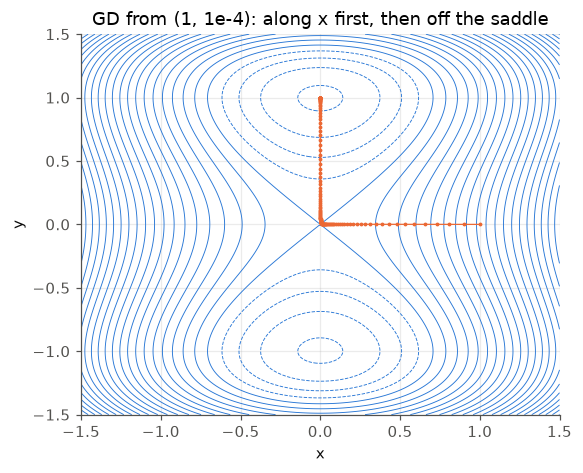

In [4]:
# Figure: the saddle f(x, y) = (x^2 - y^2)/2 + y^4/4 and one escaping trajectory
xx, yy = np.meshgrid(np.linspace(-1.5, 1.5, 200), np.linspace(-1.5, 1.5, 200)); zz = (xx**2 - yy**2) / 2 + yy**4 / 4
p = np.array([1.0, 1e-4]); traj = [p.copy()]
for t in range(200): p = p - eta * gsad(p); traj.append(p.copy())
traj = np.array(traj); plt.figure(figsize=(5.4, 4.4)); plt.contour(xx, yy, zz, levels=25, colors=[C1], linewidths=0.6)
plt.plot(traj[:, 0], traj[:, 1], ".-", color=C2, ms=3, lw=0.8); plt.title("GD from (1, 1e-4): along x first, then off the saddle"); plt.xlabel("x"); plt.ylabel("y"); plt.show()

### §24 — Polyak–Łojasiewicz
A function concave on 38% of the line, PL on all of it: gradient descent converges at (better than) the PL rate.

In [5]:
sec(24, "The Polyak–Łojasiewicz inequality: a non-convex function GD solves at a linear rate, with its PL constant measured and used")
# f(x) = x^2 + 3 sin^2(x) (Karimi, Nutini & Schmidt 2016): non-convex, f* = 0 at x = 0, satisfies PL with mu = 1/32 (their bound); L = 8
def f_pl(x): return x * x + 3 * np.sin(x) ** 2
def g_pl(x): return 2 * x + 3 * np.sin(2 * x)
xs = np.linspace(-20, 20, 400001)
ratio = (0.5 * g_pl(xs) ** 2) / np.where(f_pl(xs) > 1e-12, f_pl(xs), np.nan)
mu_pl = np.nanmin(ratio)
print(f"  f(x) = x^2 + 3 sin^2 x: measured PL constant mu = min (1/2)|f'|^2 / (f - f*) over [-20, 20] = {mu_pl:.4f} (paper's bound 1/32 = {1/32:.4f});  L = 8;  f'' < 0 on {np.mean(2 + 6*np.cos(2*xs) < 0)*100:.1f}% of the line")
print("      t    f(x_t) from x0 = 10 (GD, eta = 1/L)   PL bound (1 - mu/L)^t f(x0)")
x = 10.0; f0 = f_pl(x)
for t in range(1, 16):
    x = x - g_pl(x) / 8
    if t in (1, 2, 3, 5, 8, 10, 12, 15):
        print(f"  {t:5d}    {f_pl(x):12.4e}                        {(1 - mu_pl/8)**t * f0:12.4e}")
print("  (the bound is a bound: near 0 the step 1/L is Newton's step for this f, so the real rate is superlinear; the guarantee is linear and holds on the whole line, including the 38% of it where f is concave)")


=== §24 The Polyak–Łojasiewicz inequality: a non-convex function GD solves at a linear rate, with its PL constant measured and used ===
  f(x) = x^2 + 3 sin^2 x: measured PL constant mu = min (1/2)|f'|^2 / (f - f*) over [-20, 20] = 0.1755 (paper's bound 1/32 = 0.0312);  L = 8;  f'' < 0 on 37.9% of the line
      t    f(x_t) from x0 = 10 (GD, eta = 1/L)   PL bound (1 - mu/L)^t f(x0)
      1      5.2998e+01                          9.8674e+01
      2      2.7752e+01                          9.6509e+01
      3      1.7203e+01                          9.4392e+01
      5      6.9218e+00                          9.0295e+01
      8      5.6281e+00                          8.4481e+01
     10      1.8366e+00                          8.0814e+01
     12      2.4068e-05                          7.7307e+01
     15      0.0000e+00                          7.2329e+01
  (the bound is a bound: near 0 the step 1/L is Newton's step for this f, so the real rate is superlinear; the guarantee is linear and

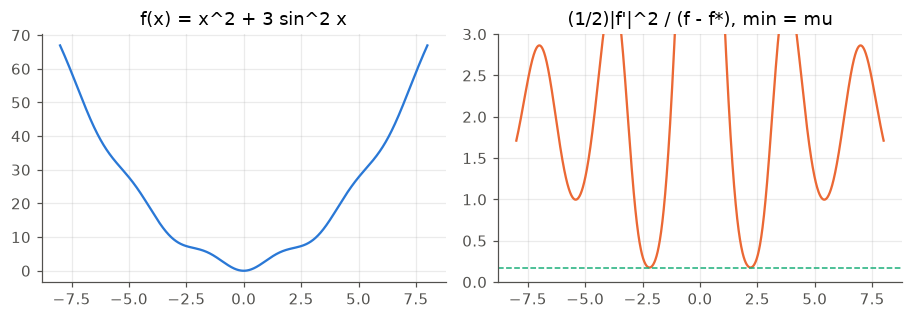

In [6]:
# Figure: the PL function and the ratio (1/2)|f'|^2 / (f - f*) that bounds its PL constant
fig, ax = plt.subplots(1, 2, figsize=(8.4, 3.0)); xs_ = np.linspace(-8, 8, 2000)
ax[0].plot(xs_, f_pl(xs_), color=C1); ax[0].set_title("f(x) = x^2 + 3 sin^2 x"); ax[1].plot(xs_, 0.5 * g_pl(xs_)**2 / np.maximum(f_pl(xs_), 1e-12), color=C2); ax[1].axhline(mu_pl, color=C3, ls="--", lw=1); ax[1].set_ylim(0, 3); ax[1].set_title("(1/2)|f'|^2 / (f - f*), min = mu"); plt.show()

### §25 — Autodiff at a kink
Three conventions for $\mathrm{relu}'(0)$ give three "derivatives" of the identity function at the origin; the kink has measure zero, which is the conservative-gradient theorem.

In [7]:
sec(25, "Nonsmooth: what autodiff returns at a kink depends on a convention, and the conservative-gradient theorem is why that is allowed")
# h(x) = relu(x) - relu(-x) = x for every real x, so h'(0) = 1. Autodiff with relu'(0) := 0 returns 0; with relu'(0) := 1 returns 2.
def relu(x): return np.maximum(x, 0.0)
def relu_prime(x, at0): return np.where(x > 0, 1.0, np.where(x < 0, 0.0, at0))
for at0 in (0.0, 0.5, 1.0):
    hp = relu_prime(0.0, at0) - relu_prime(-0.0, at0) * (-1)
    print(f"  relu'(0) := {at0}:  autodiff h'(0) = {hp:+.1f}   (true derivative of h(x) = x is +1)")
# on a random line through 0 the kink has measure zero: the fraction of sampled points where the convention matters
xs = rng.standard_normal(10 ** 6)
print(f"  of 10^6 Gaussian inputs, exactly {np.sum(xs == 0.0)} hit the kink: the convention is invisible almost everywhere, which is the theorem (Bolte & Pauwels 2021)")
# a 2-layer ReLU net on a kink: the loss landscape is piecewise smooth; count distinct activation patterns along a segment
W1 = rng.standard_normal((16, 2)); b1 = rng.standard_normal(16)
pts = np.linspace(-1, 1, 10001)[:, None] * np.array([[1.0, 0.7]])
pat = (pts @ W1.T + b1 > 0)
changes = np.sum(np.any(pat[1:] != pat[:-1], axis=1))
print(f"  a 16-unit ReLU layer along one input segment: {changes} activation-pattern changes in 10,001 points — {changes} kinks of the loss on that line, each of measure zero")


=== §25 Nonsmooth: what autodiff returns at a kink depends on a convention, and the conservative-gradient theorem is why that is allowed ===
  relu'(0) := 0.0:  autodiff h'(0) = +0.0   (true derivative of h(x) = x is +1)
  relu'(0) := 0.5:  autodiff h'(0) = +1.0   (true derivative of h(x) = x is +1)
  relu'(0) := 1.0:  autodiff h'(0) = +2.0   (true derivative of h(x) = x is +1)
  of 10^6 Gaussian inputs, exactly 0 hit the kink: the convention is invisible almost everywhere, which is the theorem (Bolte & Pauwels 2021)
  a 16-unit ReLU layer along one input segment: 9 activation-pattern changes in 10,001 points — 9 kinks of the loss on that line, each of measure zero


---
## §7 — Landscapes

### §26 — Benign landscapes
Rank-2 matrix sensing from 100 random starts: all reach $M^\star$ at a linear rate; with the factor over-parameterised to rank 4, all head there at a sublinear one.

In [8]:
sec(26, "Benign landscapes: rank-r matrix sensing (Burer–Monteiro) from 100 random starts, exact rank and over-parameterised")
k, r_true, m = 12, 2, 300
Ut = rng.standard_normal((k, r_true)); Mstar = Ut @ Ut.T
A2 = rng.standard_normal((m, k, k)); A2 = (A2 + A2.transpose(0, 2, 1)) / sqrt(2)
y2 = np.einsum('mij,ij->m', A2, Mstar)
def f_bm(U): r = np.einsum('mij,ij->m', A2, U @ U.T) - y2; return np.sum(r * r) / (4 * m)
def g_bm(U): r = np.einsum('mij,ij->m', A2, U @ U.T) - y2; return np.einsum('m,mij->ij', r, A2) @ U / m
for rr in (2, 4):
    ok4 = ok2 = 0; its = []; errs = []
    for trial in range(100):
        U = rng.standard_normal((k, rr)) * 0.1
        for t in range(20000):
            U = U - 0.02 * g_bm(U)
            if f_bm(U) < 1e-10: break
        e = np.linalg.norm(U @ U.T - Mstar); errs.append(e); ok4 += e < 1e-4; ok2 += e < 1e-2; its.append(t + 1)
    print(f"  factor rank {rr} (truth {r_true}): ||U U^T - M*||_F < 1e-4 in {ok4}/100 runs, < 1e-2 in {ok2}/100; steps to f < 1e-10: median {int(np.median(its))}, max {max(its)}; median final error {np.median(errs):.2e}")
print("  (every run heads to M*; the exact-rank runs get there at a linear rate, the over-parameterised runs at a sublinear one — the extra directions are flat, which is the price of r > r*)")
print("  (the theorem: every second-order stationary point is global when m is large enough relative to k r; the saddles are strict — Ge, Jin & Zheng 2017)")


=== §26 Benign landscapes: rank-r matrix sensing (Burer–Monteiro) from 100 random starts, exact rank and over-parameterised ===


  factor rank 2 (truth 2): ||U U^T - M*||_F < 1e-4 in 100/100 runs, < 1e-2 in 100/100; steps to f < 1e-10: median 52, max 69; median final error 1.59e-05


  factor rank 4 (truth 2): ||U U^T - M*||_F < 1e-4 in 0/100 runs, < 1e-2 in 100/100; steps to f < 1e-10: median 20000, max 20000; median final error 1.30e-03
  (every run heads to M*; the exact-rank runs get there at a linear rate, the over-parameterised runs at a sublinear one — the extra directions are flat, which is the price of r > r*)
  (the theorem: every second-order stationary point is global when m is large enough relative to k r; the saddles are strict — Ge, Jin & Zheng 2017)


### §27 — Lazy versus feature learning
Under NTK scaling the first layer's relative movement falls like $1/\sqrt m$ with width; under mean-field scaling it stays of order one.

In [9]:
sec(27, "Lazy versus feature learning: a two-layer ReLU net at widths 64 .. 4096 under NTK scaling (1/sqrt m) and mean-field scaling (1/m)")
# 1-D regression y = sin(2 pi x) on 40 points; manual gradients; the step is 0.5 under NTK scaling and 0.05 m under mean-field scaling (so that each neuron can move O(1))
xtr = np.linspace(-1, 1, 40); ytr = np.sin(2 * pi * xtr)
def train(mw, scaling, steps=3000):
    w1 = rng.standard_normal(mw); b1_ = rng.standard_normal(mw); w2 = rng.standard_normal(mw)
    w10, b10, w20 = w1.copy(), b1_.copy(), w2.copy()
    scale = 1 / sqrt(mw) if scaling == "ntk" else 1 / mw
    eta = 0.5 if scaling == "ntk" else 0.05 * mw
    for t in range(steps):
        pre = np.outer(xtr, w1) + b1_; act = np.maximum(pre, 0); out = scale * act @ w2
        err = out - ytr
        gw2 = scale * act.T @ err / len(xtr)
        gact = scale * np.outer(err, w2) * (pre > 0)
        gw1 = (gact * xtr[:, None]).sum(0) / len(xtr); gb1 = gact.sum(0) / len(xtr)
        w1 -= eta * gw1; b1_ -= eta * gb1; w2 -= eta * gw2
    pre = np.outer(xtr, w1) + b1_; out = scale * np.maximum(pre, 0) @ w2
    rel = np.linalg.norm(w1 - w10) / np.linalg.norm(w10)
    return 0.5 * np.mean((out - ytr) ** 2), rel, np.mean((pre > 0) != (np.outer(xtr, w10) + b10 > 0))
print("   width      NTK: loss     ||w1 - w1_0||/||w1_0||   activations flipped      mean-field: loss     rel. movement   flipped")
for mw in (64, 256, 1024, 4096):
    ln, rn, fn = train(mw, "ntk"); lm, rm, fm = train(mw, "mf")
    print(f"  {mw:6d}      {ln:9.5f}        {rn:9.5f}               {fn:7.4f}             {lm:9.5f}           {rm:9.5f}      {fm:7.4f}")
print("  (NTK scaling: the relative movement shrinks with width — the kernel regime; mean-field: it does not — features move)")


=== §27 Lazy versus feature learning: a two-layer ReLU net at widths 64 .. 4096 under NTK scaling (1/sqrt m) and mean-field scaling (1/m) ===
   width      NTK: loss     ||w1 - w1_0||/||w1_0||   activations flipped      mean-field: loss     rel. movement   flipped


      64        0.02674          0.95887                0.0859               0.08401             2.78258       0.0773


     256        0.04241          0.37301                0.0573               0.07987             2.62832       0.0637


    1024        0.03593          0.16129                0.0461               0.08109             2.67249       0.0650


    4096        0.02028          0.07283                0.0371               0.08093             2.72091       0.0637
  (NTK scaling: the relative movement shrinks with width — the kernel regime; mean-field: it does not — features move)


### §28 — The edge of stability
Full-batch gradient descent on a 32-unit tanh network: the sharpness rises until it meets $2/\eta$ and then sits there to three digits while the loss falls non-monotonically.

In [10]:
sec(28, "Edge of stability: full-batch GD on a small tanh network drives the top Hessian eigenvalue to 2/eta and holds it there")
# 1-D regression, 1 hidden layer of 32 tanh units, 50 points; Hessian top eigenvalue by power iteration on finite-difference Hessian-vector products
xe = np.linspace(-2, 2, 50); ye = np.sin(3 * xe) + 0.3 * xe ** 2
H = 32
def unpack(th): return th[:H], th[H:2 * H], th[2 * H:3 * H], th[3 * H]
def loss_e(th):
    w1, b1_, w2, b2 = unpack(th); return 0.5 * np.mean((np.tanh(np.outer(xe, w1) + b1_) @ w2 + b2 - ye) ** 2)
def grad_e(th):
    w1, b1_, w2, b2 = unpack(th); pre = np.outer(xe, w1) + b1_; act = np.tanh(pre); out = act @ w2 + b2; err = (out - ye) / len(xe)
    gw2 = act.T @ err; gb2 = err.sum(); gact = np.outer(err, w2) * (1 - act ** 2)
    return np.concatenate([(gact * xe[:, None]).sum(0), gact.sum(0), gw2, [gb2]])
def top_eig(th, iters=60):
    v = rng.standard_normal(len(th)); v /= np.linalg.norm(v); lam_ = 0.0; h = 1e-4
    for _ in range(iters):
        hv = (grad_e(th + h * v) - grad_e(th - h * v)) / (2 * h); lam_ = v @ hv; v = hv / (np.linalg.norm(hv) + 1e-30)
    return lam_
th0 = np.concatenate([rng.standard_normal(H), rng.standard_normal(H) * 0.5, rng.standard_normal(H) / sqrt(H) * 0.1, [0.0]])
print(f"  initial top Hessian eigenvalue (sharpness): {top_eig(th0):.3f}, initial loss {loss_e(th0):.4f}")
for eta in (0.05, 0.1, 0.2):
    th = th0.copy(); rec = []
    for t in range(1, 10001):
        th = th - eta * grad_e(th)
        if t in (200, 1000, 3000, 6000, 10000): rec.append((t, loss_e(th), top_eig(th)))
    print(f"  eta = {eta:4.2f}, 2/eta = {2/eta:5.1f}:  " + "  ".join(f"t={t}: loss {l:.4f} sharp {s:5.2f}" for t, l, s in rec))
print("  (sharpness rises until it meets 2/eta and then hovers there while the loss keeps falling non-monotonically — Cohen et al. 2021; at eta = 0.05 the run never reaches 2/eta = 40 and sits where progressive sharpening leaves it)")


=== §28 Edge of stability: full-batch GD on a small tanh network drives the top Hessian eigenvalue to 2/eta and holds it there ===
  initial top Hessian eigenvalue (sharpness): 11.711, initial loss 0.4446


  eta = 0.05, 2/eta =  40.0:  t=200: loss 0.0667 sharp 11.90  t=1000: loss 0.0373 sharp 12.37  t=3000: loss 0.0265 sharp 13.15  t=6000: loss 0.0141 sharp 14.18  t=10000: loss 0.0035 sharp 15.49


  eta = 0.10, 2/eta =  20.0:  t=200: loss 0.0479 sharp 12.04  t=1000: loss 0.0306 sharp 12.81  t=3000: loss 0.0141 sharp 14.18  t=6000: loss 0.0020 sharp 15.95  t=10000: loss 0.0006 sharp 16.93


  eta = 0.20, 2/eta =  10.0:  t=200: loss 0.0437 sharp  8.67  t=1000: loss 0.0227 sharp 10.29  t=3000: loss 0.0072 sharp 10.25  t=6000: loss 0.0026 sharp  9.98  t=10000: loss 0.0043 sharp 10.00
  (sharpness rises until it meets 2/eta and then hovers there while the loss keeps falling non-monotonically — Cohen et al. 2021; at eta = 0.05 the run never reaches 2/eta = 40 and sits where progressive sharpening leaves it)


### §29 — Implicit bias on separable data
Gradient descent turns toward the $\ell_2$ max-margin direction at a $1/\log t$ rate, normalised GD at a polynomial one, and sign descent goes straight to the $\ell_\infty$ max-margin direction, $33°$ away. The slow cell of this notebook.

In [11]:
sec(29, "Implicit bias on separable data: GD on the logistic loss turns toward the l2 max-margin direction slowly, normalised GD fast, and sign descent toward a different margin")
n = 60
Xi = 0.5 * rng.standard_normal((n, 2)) + np.array([3.0, 1.0]); yi = np.ones(n)
Xi2 = 0.5 * rng.standard_normal((n, 2)) - np.array([3.0, 1.0]); Xi = np.vstack([Xi, Xi2]); yi = np.concatenate([yi, -np.ones(n)])
# class means at (3, 1): the l2 max-margin direction leans along the means, the l_inf one (an LP over the square) toward the diagonal
Q = (yi[:, None] * Xi) @ (yi[:, None] * Xi).T; a = np.zeros(2 * n); st = 1 / np.linalg.eigvalsh(Q).max()
for t in range(50000): a = np.maximum(a + st * (1 - Q @ a), 0)     # hard-margin SVM dual (bias-free): l2 max-margin direction
w_svm = (a * yi) @ Xi; w_svm /= np.linalg.norm(w_svm)
def margin(w, norm): return np.min(yi * (Xi @ w)) / norm(w)
angs = np.linspace(0, 2 * pi, 36001)
best_inf = max(angs, key=lambda th_: margin(np.array([math.cos(th_), math.sin(th_)]), lambda w: np.abs(w).max()))
w_inf = np.array([math.cos(best_inf), math.sin(best_inf)])
print(f"  data separable: min_i y_i <w_svm, x_i> = {np.min(yi * (Xi @ w_svm)):.4f} > 0")
print(f"  l2 max-margin direction {w_svm} (l2 margin {margin(w_svm, np.linalg.norm):.4f}); l_inf max-margin direction {w_inf} (l_inf margin {margin(w_inf, lambda w: np.abs(w).max()):.4f}); angle between them {math.degrees(math.acos(abs(w_svm @ w_inf))):.2f} deg")
def grad_log(w): z = yi * (Xi @ w); return -(Xi * (yi / (1 + np.exp(z)))[:, None]).mean(0)
def grad_dir(w):                                                 # the gradient up to a positive factor, computed in the log domain so it never underflows
    z = yi * (Xi @ w); lw = -np.logaddexp(0, z); wt = np.exp(lw - lw.max()); return -(Xi * (yi * wt)[:, None]).mean(0)
def ang(u, v): return math.degrees(math.acos(min(1.0, abs(u @ v) / (np.linalg.norm(u) * np.linalg.norm(v)))))
w = np.zeros(2); wn = np.zeros(2); ws = np.zeros(2)
print("        t    GD: angle to l2-mm   ||w||    normalised GD: angle to l2-mm    sign descent: angle to l_inf-mm   angle to l2-mm   l_inf margin of ws / best")
for t in range(1, 10 ** 5 + 1):
    w = w - 0.5 * grad_log(w)
    gd_ = grad_dir(wn); wn = wn - 0.5 * gd_ / np.linalg.norm(gd_)
    ws = ws - 0.01 * np.sign(grad_dir(ws))
    if t in (10 ** 2, 10 ** 3, 10 ** 4, 10 ** 5):
        print(f"  {t:8d}    {ang(w, w_svm):10.3f}        {np.linalg.norm(w):7.3f}          {ang(wn, w_svm):10.3f}                    {ang(ws, w_inf):10.3f}                 {ang(ws, w_svm):10.3f}        {margin(ws, lambda v: np.abs(v).max())/margin(w_inf, lambda v: np.abs(v).max()):.4f}")
print("  (GD's direction converges at a 1/log t rate — Soudry et al. 2018 — which is why its angle barely moves after t = 10^4 while ||w|| grows like log t; normalised GD converges in direction at a polynomial rate — Nacson et al. 2019; sign descent is steepest descent in the l_inf norm and heads for the l_inf margin — Gunasekar et al. 2018)")


=== §29 Implicit bias on separable data: GD on the logistic loss turns toward the l2 max-margin direction slowly, normalised GD fast, and sign descent toward a different margin ===


  data separable: min_i y_i <w_svm, x_i> = 1.4950 > 0
  l2 max-margin direction [0.9794 0.2018] (l2 margin 1.4950); l_inf max-margin direction [0.7071 0.7071] (l_inf margin 1.7660); angle between them 33.36 deg
        t    GD: angle to l2-mm   ||w||    normalised GD: angle to l2-mm    sign descent: angle to l_inf-mm   angle to l2-mm   l_inf margin of ws / best
       100         8.060          2.091               0.889                         0.000                     33.357        1.0000
      1000         7.774          2.998               0.089                         0.000                     33.357        1.0000
     10000         7.257          4.035               0.009                         0.000                     33.357        1.0000


    100000         6.537          5.216               0.001                         0.000                     33.357        1.0000
  (GD's direction converges at a 1/log t rate — Soudry et al. 2018 — which is why its angle barely moves after t = 10^4 while ||w|| grows like log t; normalised GD converges in direction at a polynomial rate — Nacson et al. 2019; sign descent is steepest descent in the l_inf norm and heads for the l_inf margin — Gunasekar et al. 2018)


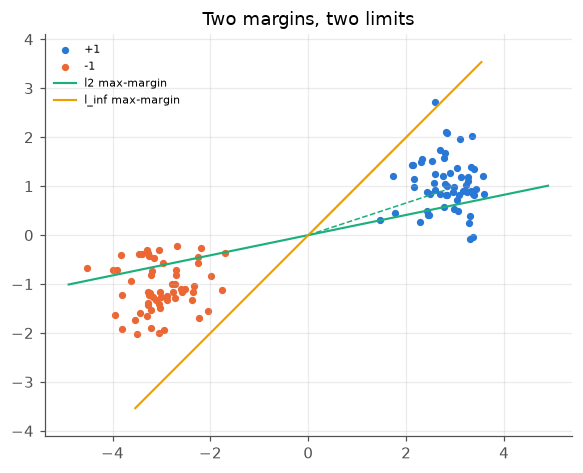

In [12]:
# Figure: the data, the two max-margin directions, and where the three methods ended
plt.figure(figsize=(5.4, 4.4)); plt.scatter(Xi[yi > 0, 0], Xi[yi > 0, 1], c=C1, s=14, label="+1"); plt.scatter(Xi[yi < 0, 0], Xi[yi < 0, 1], c=C2, s=14, label="-1")
for v, col, lab in ((w_svm, C3, "l2 max-margin"), (w_inf, C4, "l_inf max-margin")): plt.plot([-5 * v[0], 5 * v[0]], [-5 * v[1], 5 * v[1]], color=col, lw=1.4, label=lab)
for v, col, lab in ((w / np.linalg.norm(w), C3, "GD at 1e5"), (ws / np.linalg.norm(ws), C4, "sign descent at 1e5")): plt.plot([0, 3 * v[0]], [0, 3 * v[1]], "--", color=col, lw=1)
plt.legend(fontsize=7); plt.axis("equal"); plt.title("Two margins, two limits"); plt.show()

### §30 — Sharpness is not a property of the function
The same two-layer linear network, rescaled: loss zero in every row, top Hessian eigenvalue $2$, $100$, $10{,}000$.

In [13]:
sec(30, "Sharpness is not reparametrisation-invariant (Dinh et al. 2017): the same function, Hessian top eigenvalue multiplied by alpha^2")
# f(a, b) = 1/2 E (a b x - y)^2 with x ~ N(0,1), y = c x: loss = 1/2 (ab - c)^2 (+ const); the function x -> abx is unchanged by (a, b) -> (alpha a, b/alpha)
c = 1.0
def hess_ab(a_, b_):
    return np.array([[b_ ** 2, 2 * a_ * b_ - c], [2 * a_ * b_ - c, a_ ** 2]])
for alpha in (1.0, 10.0, 100.0):
    a_, b_ = alpha * 1.0, 1.0 / alpha                       # a b = c = 1: a global minimum in every case
    ev = np.linalg.eigvalsh(hess_ab(a_, b_))
    print(f"  (a, b) = ({a_:6.2f}, {b_:6.4f}): a b = {a_*b_:.1f}, loss 0, Hessian eigenvalues {ev}, top = {ev[-1]:.4f}, trace = {np.trace(hess_ab(a_, b_)):.4f}")
print("  (every row is the same predictor with the same loss on every input; 'flat' is a statement about coordinates, not about the function)")


=== §30 Sharpness is not reparametrisation-invariant (Dinh et al. 2017): the same function, Hessian top eigenvalue multiplied by alpha^2 ===
  (a, b) = (  1.00, 1.0000): a b = 1.0, loss 0, Hessian eigenvalues [0. 2.], top = 2.0000, trace = 2.0000
  (a, b) = ( 10.00, 0.1000): a b = 1.0, loss 0, Hessian eigenvalues [  0.   100.01], top = 100.0100, trace = 100.0100
  (a, b) = (100.00, 0.0100): a b = 1.0, loss 0, Hessian eigenvalues [    0.     10000.0001], top = 10000.0001, trace = 10000.0001
  (every row is the same predictor with the same loss on every input; 'flat' is a statement about coordinates, not about the function)


### §31 — Linear mode connectivity
No loss barrier between two SGD runs from one initialisation; a barrier of five times the endpoint loss between runs from two.

In [14]:
sec(31, "Linear mode connectivity: the loss barrier between two SGD runs from the same initialisation versus from different ones")
# 2-D two-moons-like data, 1 hidden layer of 64 ReLU units, SGD with different data orders
nn_ = 400
tt = rng.uniform(0, pi, nn_ // 2)
Xm = np.vstack([np.c_[np.cos(tt), np.sin(tt)], np.c_[1 - np.cos(tt), 0.5 - np.sin(tt)]]) + 0.1 * rng.standard_normal((nn_, 2))
ym = np.concatenate([np.ones(nn_ // 2), -np.ones(nn_ // 2)])
Hm_ = 64
def init(): return [rng.standard_normal((2, Hm_)) / sqrt(2), np.zeros(Hm_), rng.standard_normal(Hm_) / sqrt(Hm_), 0.0]
def fwd(p, X): return np.maximum(X @ p[0] + p[1], 0) @ p[2] + p[3]
def loss_m(p, X=Xm, y=ym): return np.mean(np.logaddexp(0, -y * fwd(p, X)))
def sgd(p, epochs=60, B=16, eta=0.1):
    p = [q.copy() if hasattr(q, 'copy') else q for q in p]
    for ep in range(epochs):
        perm = rng.permutation(nn_)
        for i in range(0, nn_, B):
            idx = perm[i:i + B]; X = Xm[idx]; y = ym[idx]
            pre = X @ p[0] + p[1]; act = np.maximum(pre, 0); out = act @ p[2] + p[3]
            err = -y / (1 + np.exp(y * out)) / len(idx)
            gw2 = act.T @ err; gb2 = err.sum(); gact = np.outer(err, p[2]) * (pre > 0)
            p[0] -= eta * X.T @ gact; p[1] -= eta * gact.sum(0); p[2] -= eta * gw2; p[3] -= eta * gb2
    return p
def barrier(pa, pb):
    ls = [loss_m([(1 - s) * a + s * b for a, b in zip(pa, pb)]) for s in np.linspace(0, 1, 21)]
    return max(ls) - max(ls[0], ls[-1]), ls[10]
p0 = init(); pA = sgd(p0); pB = sgd(p0); pC = sgd(init())
bAB, midAB = barrier(pA, pB); bAC, midAC = barrier(pA, pC)
print(f"  end losses: A {loss_m(pA):.4f}, B {loss_m(pB):.4f} (same init, different order), C {loss_m(pC):.4f} (different init)")
print(f"  barrier along the segment A–B: {bAB:.4f} (midpoint loss {midAB:.4f});  A–C: {bAC:.4f} (midpoint loss {midAC:.4f})")
print("  (same-init runs are linearly connected, different-init runs are not — Frankle et al. 2020; permuting C's hidden units is what Git Re-Basin does)")


=== §31 Linear mode connectivity: the loss barrier between two SGD runs from the same initialisation versus from different ones ===


  end losses: A 0.0611, B 0.0607 (same init, different order), C 0.0791 (different init)
  barrier along the segment A–B: 0.0000 (midpoint loss 0.0609);  A–C: 0.2550 (midpoint loss 0.3341)
  (same-init runs are linearly connected, different-init runs are not — Frankle et al. 2020; permuting C's hidden units is what Git Re-Basin does)


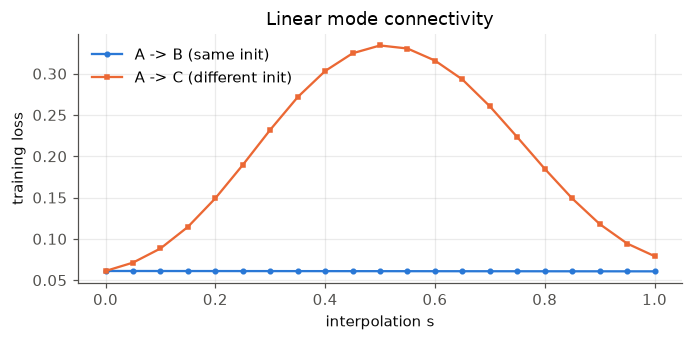

In [15]:
# Figure: the loss along the two segments
ss = np.linspace(0, 1, 21); lab_ = [loss_m([(1 - s) * a_ + s * b_ for a_, b_ in zip(pA, pB)]) for s in ss]; lac_ = [loss_m([(1 - s) * a_ + s * b_ for a_, b_ in zip(pA, pC)]) for s in ss]
plt.figure(figsize=(6.4, 3.2)); plt.plot(ss, lab_, "o-", color=C1, ms=3, label="A -> B (same init)"); plt.plot(ss, lac_, "s-", color=C2, ms=3, label="A -> C (different init)")
plt.xlabel("interpolation s"); plt.ylabel("training loss"); plt.legend(); plt.title("Linear mode connectivity"); plt.show()

---
## §8 — Global optimization

### §32 — Branch-and-bound on Rastrigin
A Lipschitz lower bound certifies the global minimum to within $\varepsilon = 1$ in $10^2$ boxes in one dimension, $10^5$ in three, and not within the cap in four: the exponential, measured. The verdicts are computed in ordinary float64 without directed rounding: the bound $f(c) - \mathrm{Lip}\cdot\text{radius}$ is sound in exact arithmetic, and "certified" here is a numerical certificate in that model, not a validated floating-point proof (which needs outward-rounded interval arithmetic or an error enclosure — §8.1 of the article).

In [16]:
sec(32, "Certified global optimisation by branch-and-bound with a Lipschitz lower bound on Rastrigin: boxes explored grow exponentially with dimension")
import heapq
def rastrigin(x): return 10 * len(x) + np.sum(x * x - 10 * np.cos(2 * pi * x))
def bnb(dim, eps, max_boxes=200000):
    Lip = sqrt(dim) * (2 * 5.12 + 20 * pi)                      # per-coordinate |f'| <= 2*5.12 + 20 pi on [-5.12, 5.12]
    lo0, hi0 = -5.12 * np.ones(dim), 5.12 * np.ones(dim)
    c = (lo0 + hi0) / 2; best = rastrigin(c); best_x = c
    heap = [(best - Lip * np.linalg.norm(hi0 - lo0) / 2, 0, lo0, hi0)]; cnt = 1; k_ = 1
    while heap:
        lb, _, lo, hi = heapq.heappop(heap)
        if lb > best - eps: break                               # the global minimum is certified to within eps
        j = int(np.argmax(hi - lo)); mid = (lo[j] + hi[j]) / 2
        for a_, b_ in (((lo, np.where(np.arange(dim) == j, mid, hi))), (np.where(np.arange(dim) == j, mid, lo), hi)):
            c = (a_ + b_) / 2; fc = rastrigin(c)
            if fc < best: best, best_x = fc, c
            heapq.heappush(heap, (fc - Lip * np.linalg.norm(b_ - a_) / 2, k_, a_, b_)); k_ += 1; cnt += 1
            if cnt >= max_boxes: return best, best_x, cnt, False
    return best, best_x, cnt, True
print("   dim   boxes to certify f* within eps = 1.0   certified f*   (true f* = 0 at the origin)")
for dim in (1, 2, 3, 4):
    best, bx, cnt, done = bnb(dim, 1.0)
    print(f"  {dim:4d}   {cnt:10d}{'' if done else ' (cap hit, not certified)'}                          {best:8.4f}")
print("  (each box is split in half along its longest side; the lower bound is f(centre) - Lip * radius; a tighter bound — interval or alpha-BB — cuts the constant, not the exponent)")


=== §32 Certified global optimisation by branch-and-bound with a Lipschitz lower bound on Rastrigin: boxes explored grow exponentially with dimension ===
   dim   boxes to certify f* within eps = 1.0   certified f*   (true f* = 0 at the origin)
     1          103                            0.0000
     2         3287                            0.0000


     3        96767                            0.0000


     4       200000 (cap hit, not certified)                            0.0000
  (each box is split in half along its longest side; the lower bound is f(centre) - Lip * radius; a tighter bound — interval or alpha-BB — cuts the constant, not the exponent)


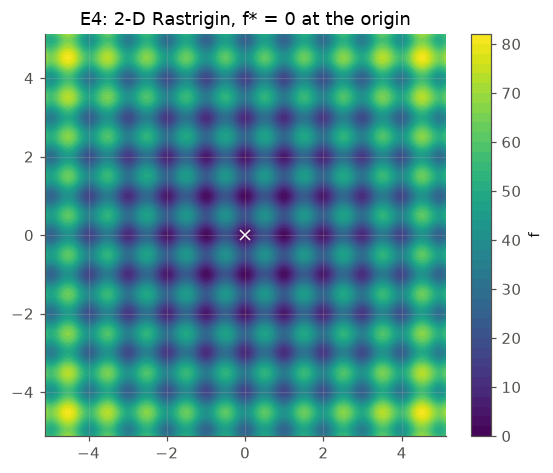

In [17]:
# Figure: the 2-D Rastrigin function (E4) and its hundred local minima
xx, yy = np.meshgrid(np.linspace(-5.12, 5.12, 300), np.linspace(-5.12, 5.12, 300)); zz = 20 + xx**2 - 10 * np.cos(2 * pi * xx) + yy**2 - 10 * np.cos(2 * pi * yy)
plt.figure(figsize=(5.2, 4.4)); plt.contourf(xx, yy, zz, levels=40, cmap="viridis"); plt.colorbar(label="f"); plt.plot(0, 0, "x", color="white"); plt.title("E4: 2-D Rastrigin, f* = 0 at the origin"); plt.show()

### §33 — Local search, annealed Langevin, restarts
Gradient descent from a uniform start reaches the global basin 1% of the time (its area); annealed Langevin 11%; 459 restarts for 99% confidence. None of it certifies anything.

In [18]:
sec(33, "Local search, annealed Langevin, and random restarts on 2-D Rastrigin: fraction of runs that end in the global basin")
def g_ras(x): return 2 * x + 20 * pi * np.sin(2 * pi * x)
def gd_run(x, steps=2000, eta=0.002):
    for _ in range(steps): x = x - eta * g_ras(x)
    return x
def sgld_run(x, steps=20000, eta=0.005, T0_=10.0):
    for t in range(steps):
        Tt = T0_ * (1 - t / steps) ** 2 + 1e-3                   # annealed temperature
        x = x - eta * g_ras(x) + sqrt(2 * eta * Tt) * rng.standard_normal(2)
        x = np.clip(x, -5.12, 5.12)
    return gd_run(x, 500)
ngd = nsg = 0; N_ = 200
for trial in range(N_):
    x0 = rng.uniform(-5.12, 5.12, 2)
    ngd += rastrigin(gd_run(x0)) < 0.5; nsg += rastrigin(sgld_run(x0)) < 0.5
print(f"  GD from a uniform random start: global basin reached in {ngd/N_:.3f} ± {se_prop(ngd, N_):.3f} of {N_} runs  (basin of the origin has width ~1 in each coordinate on a 10.24-wide square: (1/10.24)^2 = {(1/10.24)**2:.4f} by area)")
print(f"  annealed Langevin (T from 10 to ~0 over 20,000 steps, eta = 0.005) then GD: {nsg/N_:.3f} ± {se_prop(nsg, N_):.3f}   (the best of a small grid over T0 and eta; a factor of ~10 over local search, and nowhere near reliable)")
k_restart = int(math.ceil(log(0.01) / log(1 - max(ngd, 1) / N_)))
print(f"  random restarts of plain GD needed for 99% success at the measured rate: {k_restart}  (restarts are the cheapest global method when the basin is not tiny; none of this certifies anything)")


=== §33 Local search, annealed Langevin, and random restarts on 2-D Rastrigin: fraction of runs that end in the global basin ===


  GD from a uniform random start: global basin reached in 0.010 ± 0.007 of 200 runs  (basin of the origin has width ~1 in each coordinate on a 10.24-wide square: (1/10.24)^2 = 0.0095 by area)
  annealed Langevin (T from 10 to ~0 over 20,000 steps, eta = 0.005) then GD: 0.110 ± 0.022   (the best of a small grid over T0 and eta; a factor of ~10 over local search, and nowhere near reliable)
  random restarts of plain GD needed for 99% success at the measured rate: 459  (restarts are the cheapest global method when the basin is not tiny; none of this certifies anything)


### §34 — Bayesian optimization against random search
A GP with expected improvement, 60 evaluations: better than random search on average, by about 1.6 standard errors of the mean difference over ten trials — suggestive, not significant — and nowhere near the optimum. A regret bound under the prior, not a certificate.

In [19]:
sec(34, "Bayesian optimisation (GP + expected improvement) versus random search on 2-D Rastrigin with 60 evaluations (W28 bridge)")
def Phi(x): return 0.5 * (1 + math.erf(x / sqrt(2)))
def phi(x): return exp(-x * x / 2) / sqrt(2 * pi)
def kern(Xa, Xb, ell=0.6): d2 = np.sum((Xa[:, None, :] - Xb[None, :, :]) ** 2, -1); return np.exp(-d2 / (2 * ell * ell))
bo_best, rs_best = [], []
cand = rng.uniform(-5.12, 5.12, (4000, 2))
for trial in range(10):
    Xo = rng.uniform(-5.12, 5.12, (5, 2)); yo = np.array([rastrigin(x) for x in Xo])
    for it in range(55):
        mu_y, sd_y = yo.mean(), yo.std() + 1e-9; yn = (yo - mu_y) / sd_y
        K = kern(Xo, Xo) + 1e-6 * np.eye(len(Xo)); Linv = np.linalg.inv(np.linalg.cholesky(K))
        alpha_ = Linv.T @ (Linv @ yn)
        Ks = kern(cand, Xo); mu_c = Ks @ alpha_; v = Linv @ Ks.T; var_c = np.maximum(1 - np.sum(v * v, 0), 1e-12); sd_c = np.sqrt(var_c)
        zbest = yn.min(); zc = (zbest - mu_c) / sd_c
        ei = sd_c * (zc * np.vectorize(Phi)(zc) + np.vectorize(phi)(zc))
        xnew = cand[np.argmax(ei)]; Xo = np.vstack([Xo, xnew]); yo = np.append(yo, rastrigin(xnew))
    bo_best.append(yo.min())
    rs = np.array([rastrigin(x) for x in rng.uniform(-5.12, 5.12, (60, 2))]); rs_best.append(rs.min())
print(f"  best value after 60 evaluations, 10 trials: BO {np.mean(bo_best):.3f} ± {se_mean(bo_best):.3f}   random search {np.mean(rs_best):.3f} ± {se_mean(rs_best):.3f}   (f* = 0)")
diff_ = np.array(rs_best) - np.array(bo_best)
print(f"  difference random search - BO over the 10 trials: {diff_.mean():.3f} ± {se_mean(diff_):.3f} (SE of the mean difference) = {diff_.mean()/se_mean(diff_):.2f} standard errors; BO's best was lower in {int(np.sum(diff_ > 0))}/10 trials")
print("  (BO is a global method under a prior; its guarantee is a regret bound for the GP it assumed, not a certificate)")


=== §34 Bayesian optimisation (GP + expected improvement) versus random search on 2-D Rastrigin with 60 evaluations (W28 bridge) ===


  best value after 60 evaluations, 10 trials: BO 4.837 ± 1.414   random search 7.914 ± 1.263   (f* = 0)
  difference random search - BO over the 10 trials: 3.077 ± 1.907 (SE of the mean difference) = 1.61 standard errors; BO's best was lower in 6/10 trials
  (BO is a global method under a prior; its guarantee is a regret bound for the GP it assumed, not a certificate)


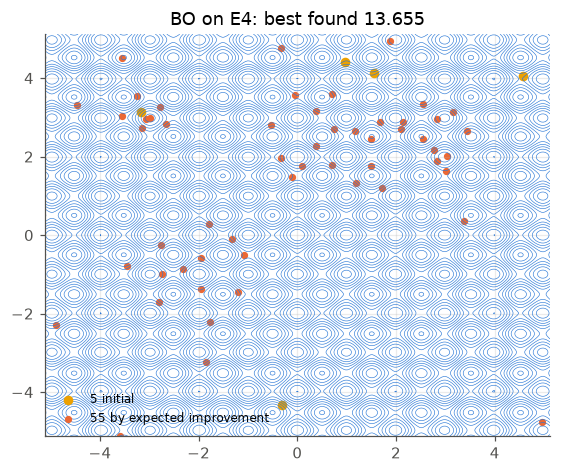

In [20]:
# Figure: where the last BO trial placed its 60 evaluations
xx, yy = np.meshgrid(np.linspace(-5.12, 5.12, 300), np.linspace(-5.12, 5.12, 300)); zz = 20 + xx**2 - 10 * np.cos(2 * pi * xx) + yy**2 - 10 * np.cos(2 * pi * yy)   # E4 grid, as in the §32 figure
plt.figure(figsize=(5.2, 4.4)); plt.contour(xx, yy, zz, levels=25, colors=[C1], linewidths=0.4); plt.scatter(Xo[:5, 0], Xo[:5, 1], c=C4, s=28, label="5 initial"); plt.scatter(Xo[5:, 0], Xo[5:, 1], c=C2, s=14, label="55 by expected improvement")
plt.legend(fontsize=8); plt.title(f"BO on E4: best found {yo.min():.3f}"); plt.show()

### §35 — Verification as certified global optimization
Interval bounds certify a small robustness radius alone, branch-and-bound on the input box certifies a larger one, and from $\varepsilon = 0.4$ a counter-example ends the search. `CERTIFIED` means the interval bound, evaluated in float64, clears zero on every leaf — sound in exact arithmetic, not a validated floating-point proof (a shipping verifier rounds outward); the grid column is the sampled minimum of the *signed* output, never a bound.

In [21]:
sec(35, "Verification as the home of certified global optimisation: interval bounds, then branch-and-bound on the input box, on a 2-16-1 ReLU network at five radii")
W1v = rng.standard_normal((16, 2)); b1v = rng.standard_normal(16) * 0.5; W2v = rng.standard_normal(16) / 4; b2v = 0.0
x0v = np.array([0.8, -0.3])
def net(x): return np.maximum(W1v @ x + b1v, 0) @ W2v + b2v
f0v = net(x0v); sgn = 1.0 if f0v > 0 else -1.0
def ibp(lo, hi):                                                 # interval bound propagation: a sound lower/upper bound on net over the box
    c = (lo + hi) / 2; r = (hi - lo) / 2
    cz = W1v @ c + b1v; rz = np.abs(W1v) @ r
    zl, zu = cz - rz, cz + rz
    al, au = np.maximum(zl, 0), np.maximum(zu, 0)
    wpos = np.maximum(W2v, 0); wneg = np.minimum(W2v, 0)
    return zl, zu, wpos @ al + wneg @ au + b2v, wpos @ au + wneg @ al + b2v
def bab(eps, cap=200000):                                         # split the input box; certify a leaf when its IBP bound is on the right side; falsify on a counter-example
    leaves = [(x0v - eps, x0v + eps)]; decided = 0; undecided = 0; nodes = 1
    while leaves:
        lo, hi = leaves.pop()
        zl, zu, olo, ohi = ibp(lo, hi)
        if sgn * (olo if sgn > 0 else ohi) > 0: decided += 1; continue
        c = (lo + hi) / 2
        corners = [np.array([a_, b_]) for a_ in (lo[0], hi[0]) for b_ in (lo[1], hi[1])]
        if any(sgn * net(p_) <= 0 for p_ in [c] + corners): return "FALSIFIED (counter-example found)", nodes, decided
        if nodes >= cap: undecided += 1; continue
        j = int(np.argmax(hi - lo)); mid = (lo[j] + hi[j]) / 2
        leaves.append((lo, np.where(np.arange(2) == j, mid, hi))); leaves.append((np.where(np.arange(2) == j, mid, lo), hi)); nodes += 2
    return ("CERTIFIED" if undecided == 0 else "undecided (node cap)"), nodes, decided
print(f"  property: sign(net(x)) = sign(net(x0)) = {'+' if sgn > 0 else '-'} for every ||x - x0||_inf <= eps;  net(x0) = {f0v:+.4f}")
print("    eps    IBP bound on sgn*net (lower)   unstable ReLUs   grid min of sgn*net (401^2)   branch-and-bound verdict                 boxes   certified leaves")
grid = np.linspace(-1, 1, 401)
for eps_v in (0.1, 0.25, 0.4, 0.5, 0.75):
    zl, zu, olo, ohi = ibp(x0v - eps_v, x0v + eps_v)
    lb = sgn * (olo if sgn > 0 else ohi); unstable = int(np.sum((zl < 0) & (zu > 0)))
    GX, GY = np.meshgrid(x0v[0] + eps_v * grid, x0v[1] + eps_v * grid)
    gmin = np.min(sgn * (np.maximum(np.stack([GX.ravel(), GY.ravel()], 1) @ W1v.T + b1v, 0) @ W2v + b2v))   # min of the SIGNED output; sgn * min(v) is wrong when sgn < 0 (companion review r1, finding A)
    verdict, nodes, dec = bab(eps_v)
    print(f"  {eps_v:5.2f}    {lb:+10.4f}                       {unstable:3d}/16          {gmin:+10.4f}                   {verdict:38s} {nodes:6d}   {dec:6d}")
print("  (interval arithmetic is sound and loose; once it says 'undecided', splitting the box tightens it, and a counter-example ends the search — the shape of alpha-beta-CROWN in miniature; VNN-COMP 2025 ran 8 tools on 25 benchmarks this way)")


=== §35 Verification as the home of certified global optimisation: interval bounds, then branch-and-bound on the input box, on a 2-16-1 ReLU network at five radii ===
  property: sign(net(x)) = sign(net(x0)) = + for every ||x - x0||_inf <= eps;  net(x0) = +0.3111
    eps    IBP bound on sgn*net (lower)   unstable ReLUs   grid min of sgn*net (401^2)   branch-and-bound verdict                 boxes   certified leaves
   0.10       +0.0724                         5/16             +0.2610                   CERTIFIED                                   1        1
   0.25       -0.3868                         8/16             +0.1351                   CERTIFIED                                  15        8
   0.40       -0.9467                         8/16             -0.0916                   FALSIFIED (counter-example found)           1        0
   0.50       -1.3200                         9/16             -0.2428                   FALSIFIED (counter-example found)           1        0
   0

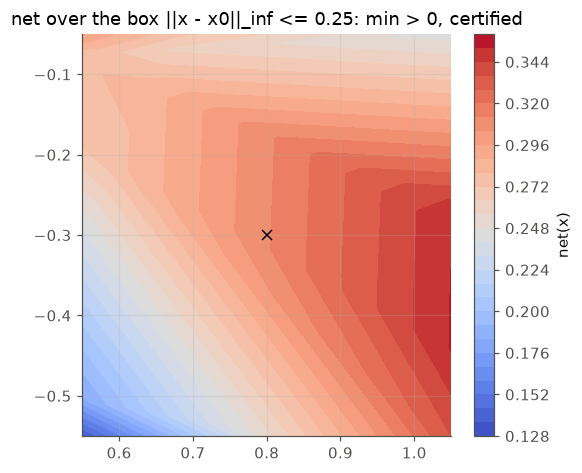

In [22]:
# Figure: the network's output over the eps = 0.25 box, with the zero level set
e_ = 0.25; gx = np.linspace(-e_, e_, 201); GX_, GY_ = np.meshgrid(x0v[0] + gx, x0v[1] + gx)
vals_ = np.maximum(np.stack([GX_.ravel(), GY_.ravel()], 1) @ W1v.T + b1v, 0) @ W2v + b2v
plt.figure(figsize=(5.2, 4.4)); plt.contourf(GX_, GY_, vals_.reshape(GX_.shape), levels=30, cmap="coolwarm"); plt.colorbar(label="net(x)"); plt.contour(GX_, GY_, vals_.reshape(GX_.shape), levels=[0], colors="k")
plt.plot(*x0v, "kx"); plt.title("net over the box ||x - x0||_inf <= 0.25: min > 0, certified"); plt.show()

### §36 — Quantisation as a second-order problem
GPTQ-style sequential rounding with Hessian compensation halves the output error of round-to-nearest while moving the weights further: it minimised the quadratic with $H$ in it.

In [23]:
sec(36, "Quantisation is a constrained second-order problem: round-to-nearest vs OBS/GPTQ-style sequential rounding with Hessian compensation on a 64-input linear layer")
din, nsamp = 64, 2000
Cx = np.linalg.cholesky(np.array([[0.8 ** abs(i - j) for j in range(din)] for i in range(din)]))
Xq = rng.standard_normal((nsamp, din)) @ Cx.T                      # correlated inputs: Hessian H = X^T X / n is far from diagonal
wq = rng.standard_normal(din)
levels = 4                                                         # 2-bit grid, symmetric
scale = np.abs(wq).max() / (levels / 2 - 0.5)
def quant(v): return np.clip(np.round(v / scale), -levels / 2, levels / 2 - 1) * scale
Hq = Xq.T @ Xq / nsamp + 1e-3 * np.eye(din)
w_rtn = quant(wq)
# GPTQ (Frantar et al. 2023) in its simplest form: quantise coordinates in order, push the error onto the remaining weights via the Hessian inverse
w_g = wq.copy(); Hinv = np.linalg.inv(Hq)
for i in range(din):
    qi = quant(np.array([w_g[i]]))[0]; err = (w_g[i] - qi) / Hinv[i, i]
    w_g[i:] -= err * Hinv[i, i:]; w_g[i] = qi
    # keep the already-quantised prefix fixed: Hinv restricted to the remaining block (Cholesky form in the paper)
    Hinv_sub = Hinv[i + 1:, i + 1:] - np.outer(Hinv[i + 1:, i], Hinv[i, i + 1:]) / Hinv[i, i]
    Hinv = np.block([[Hinv[:i + 1, :i + 1], Hinv[:i + 1, i + 1:]], [Hinv[i + 1:, :i + 1], Hinv_sub]]) if i + 1 < din else Hinv
w_g = quant(w_g)
def out_err(w): return np.mean((Xq @ (w - wq)) ** 2)
print(f"  2-bit grid ({levels} levels): output MSE round-to-nearest {out_err(w_rtn):.4f}   GPTQ-style {out_err(w_g):.4f}   (ratio {out_err(w_rtn)/out_err(w_g):.2f}x);  weight MSE RTN {np.mean((w_rtn-wq)**2):.4f} vs GPTQ {np.mean((w_g-wq)**2):.4f}")
print("  (the objective is the quadratic (w - w_q)^T H (w - w_q) over a discrete grid: minimising it exactly is an integer program; OBS/GPTQ is a greedy second-order heuristic with a closed-form compensation step)")


=== §36 Quantisation is a constrained second-order problem: round-to-nearest vs OBS/GPTQ-style sequential rounding with Hessian compensation on a 64-input linear layer ===
  2-bit grid (4 levels): output MSE round-to-nearest 8.0317   GPTQ-style 4.1450   (ratio 1.94x);  weight MSE RTN 0.1648 vs GPTQ 0.2826
  (the objective is the quadratic (w - w_q)^T H (w - w_q) over a discrete grid: minimising it exactly is an integer program; OBS/GPTQ is a greedy second-order heuristic with a closed-form compensation step)


---
## §9 and §8.5 — Minimax, and the relaxation that is exact

### §37 — Minimax is not descent
On the bilinear saddle, simultaneous gradient descent-ascent spirals out by $\sqrt{1 + \eta^2}$ per step; extragradient and optimistic gradient spiral in.

In [24]:
sec(37, "Minimax is not descent: simultaneous gradient descent-ascent spirals out of the bilinear saddle; extragradient and optimistic steps spiral in")
eta = 0.1
def run_game(kind, T=200):
    z = np.array([1.0, 1.0]); zp = z.copy()        # min_x max_y x y: the saddle is (0, 0)
    J = np.array([[0.0, 1.0], [-1.0, 0.0]])          # v(z) = (dL/dx, -dL/dy) = (y, -x)
    for t in range(T):
        if kind == "GDA": z = z - eta * J @ z
        elif kind == "alternating": x = z[0] - eta * z[1]; y = z[1] + eta * x; z = np.array([x, y])
        elif kind == "extragradient": zh = z - eta * J @ z; z = z - eta * J @ zh
        elif kind == "optimistic": zn = z - 2 * eta * J @ z + eta * J @ zp; zp, z = z, zn
    return np.linalg.norm(z)
for kind in ("GDA", "alternating", "extragradient", "optimistic"):
    print(f"  {kind:14s} ||z_200|| = {run_game(kind):12.4e}")
print(f"  simultaneous GDA multiplies ||z|| by sqrt(1 + eta^2) = {sqrt(1+eta**2):.5f} per step: {sqrt(1+eta**2)**200:.3e} after 200 (a theorem about a 2x2 matrix); extragradient contracts by sqrt(1 - eta^2 + eta^4) = {sqrt(1-eta**2+eta**4):.5f}")


=== §37 Minimax is not descent: simultaneous gradient descent-ascent spirals out of the bilinear saddle; extragradient and optimistic steps spiral in ===
  GDA            ||z_200|| =   3.8252e+00
  alternating    ||z_200|| =   1.3565e+00
  extragradient  ||z_200|| =   5.2290e-01
  optimistic     ||z_200|| =   5.1762e-01
  simultaneous GDA multiplies ||z|| by sqrt(1 + eta^2) = 1.00499 per step: 2.705e+00 after 200 (a theorem about a 2x2 matrix); extragradient contracts by sqrt(1 - eta^2 + eta^4) = 0.99504


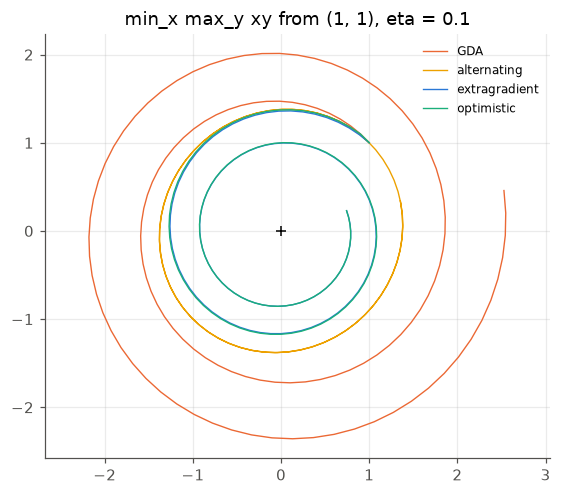

In [25]:
# Figure: the four trajectories on min_x max_y x y
def path(kind, T=120):
    z = np.array([1.0, 1.0]); zp = z.copy(); J = np.array([[0.0, 1.0], [-1.0, 0.0]]); out = [z.copy()]
    for t in range(T):
        if kind == "GDA": z = z - eta * J @ z
        elif kind == "alternating": x = z[0] - eta * z[1]; y = z[1] + eta * x; z = np.array([x, y])
        elif kind == "extragradient": zh = z - eta * J @ z; z = z - eta * J @ zh
        else: zn = z - 2 * eta * J @ z + eta * J @ zp; zp, z = z, zn
        out.append(z.copy())
    return np.array(out)
plt.figure(figsize=(5.2, 4.6))
for kind, col in (("GDA", C2), ("alternating", C4), ("extragradient", C1), ("optimistic", C3)): P = path(kind); plt.plot(P[:, 0], P[:, 1], color=col, lw=0.9, label=kind)
plt.plot(0, 0, "k+"); plt.legend(fontsize=8); plt.axis("equal"); plt.title("min_x max_y xy from (1, 1), eta = 0.1"); plt.show()

### §38 — Compressed sensing
An $\ell_1$ recovery — the lasso with $\lambda = 10^{-4}$ by FISTA, the support thresholded at $10^{-3}$, then least squares on that support (debiasing) — recovers a 10-sparse signal in $\mathbb R^{200}$ exactly from about 60 Gaussian measurements, a sharp phase transition with the constant measured; least squares never does. This is a practical proxy for the equality-constrained basis pursuit $\min\|x\|_1$ s.t. $Ax = b$ that the Candès–Romberg–Tao theorem is about, not that LP itself: the two share the exact support recovery, and the machine-precision errors are the debiased ones.

In [26]:
sec(38, "Compressed sensing: l1 recovery (lasso with lambda = 1e-4, support threshold, least-squares debias — a practical proxy for basis pursuit) of a 10-sparse signal in R^200 from m Gaussian measurements; least squares never does")
nsig, ksp = 200, 10
print("     m    lasso+threshold+debias exact recovery rate (20 trials)   min-norm l2 recovery rate   l1 median rel. error")
for m_ in (20, 40, 60, 80, 120):
    ok1 = ok2 = 0; errs = []
    for trial in range(20):
        Am = rng.standard_normal((m_, nsig)) / sqrt(m_); s = np.zeros(nsig); idx = rng.choice(nsig, ksp, replace=False); s[idx] = rng.standard_normal(ksp)
        bm = Am @ s
        # NOT the equality-constrained basis pursuit LP min ||x||_1 s.t. Ax = b that the theorem is about: FISTA on the lasso 1/2||Ax-b||^2 + lam ||x||_1
        # with a small lam, the support thresholded at 1e-3, then least squares on that support (debiasing). The machine-precision errors below are the
        # debiased ones; the lasso iterate itself is off by O(lam). Exact recovery of the support is what the two procedures share (companion review r1, finding B)
        Lm = np.linalg.eigvalsh(Am.T @ Am).max(); lam_ = 1e-4; x = np.zeros(nsig); z = x.copy(); tk = 1.0
        for t in range(3000):
            xn = prox(z - Am.T @ (Am @ z - bm) / Lm, lam_ / Lm); tn = (1 + sqrt(1 + 4 * tk * tk)) / 2
            z = xn + (tk - 1) / tn * (xn - x); x, tk = xn, tn
        supp = np.abs(x) > 1e-3
        if supp.sum() <= m_: xd = np.zeros(nsig); xd[supp] = np.linalg.lstsq(Am[:, supp], bm, rcond=None)[0]
        else: xd = x
        rel = np.linalg.norm(xd - s) / np.linalg.norm(s); errs.append(rel); ok1 += rel < 1e-4
        x2 = np.linalg.lstsq(Am, bm, rcond=None)[0]; ok2 += np.linalg.norm(x2 - s) / np.linalg.norm(s) < 1e-4
    print(f"  {m_:4d}       {ok1/20:5.2f} ± {se_prop(ok1,20):.2f}                                {ok2/20:5.2f}                      {np.median(errs):10.2e}")
print("  (the convex relaxation of an NP-hard l0 problem is exact with high probability once m >~ C k log(n/k), and k log(n/k) ~ 30 here; the theorem is about the basis-pursuit LP and leaves C unstated — the transition above, between m = 40 and 60, is this lasso+debias proxy's and only estimates C ~ 2)")


=== §38 Compressed sensing: l1 recovery (lasso with lambda = 1e-4, support threshold, least-squares debias — a practical proxy for basis pursuit) of a 10-sparse signal in R^200 from m Gaussian measurements; least squares never does ===
     m    lasso+threshold+debias exact recovery rate (20 trials)   min-norm l2 recovery rate   l1 median rel. error


    20        0.00 ± 0.00                                 0.00                        7.84e-01


    40        0.15 ± 0.08                                 0.00                        1.65e-01


    60        1.00 ± 0.00                                 0.00                        7.34e-16


    80        1.00 ± 0.00                                 0.00                        9.28e-16


   120        1.00 ± 0.00                                 0.00                        7.94e-16
  (the convex relaxation of an NP-hard l0 problem is exact with high probability once m >~ C k log(n/k), and k log(n/k) ~ 30 here; the theorem is about the basis-pursuit LP and leaves C unstated — the transition above, between m = 40 and 60, is this lasso+debias proxy's and only estimates C ~ 2)


### §39 — Over-parameterised interpolation and PL$^\ast$
A $d = 400$, $n = 50$ linear model: 350 zero Hessian eigenvalues, no strong convexity, and linear convergence anyway at the rate of the smallest eigenvalue of the $n\times n$ tangent kernel.

In [27]:
sec(39, "Over-parameterised interpolation: GD on a d > n linear model reaches zero loss at a linear rate on the data subspace — the PL* picture — and the rate is the smallest nonzero singular value")
n, d = 50, 400
Xo = rng.standard_normal((n, d)); yo = rng.standard_normal(n)
sv = np.linalg.svd(Xo, compute_uv=False); Lo = sv[0] ** 2 / n; mu_o = sv[-1] ** 2 / n
w = np.zeros(d)
print(f"  tangent kernel K = X X^T / n: largest eigenvalue {Lo:.3f}, smallest (of n = {n}) {mu_o:.3f}; PL* constant mu = {mu_o:.3f}; predicted rate (1 - mu/L)^2t")
for t in range(1, 2001):
    w = w - (1 / Lo) * Xo.T @ (Xo @ w - yo) / n
    if t in (10, 100, 500, 1000, 2000):
        print(f"  t = {t:5d}: loss {0.5*np.mean((Xo @ w - yo)**2):10.3e}   predicted {0.5*np.mean(yo**2)*(1 - mu_o/Lo)**(2*t):10.3e}")
print("  (the Hessian in weight space has d - n = 350 zero eigenvalues and the loss is not strongly convex; the condition that does the work is on the n x n kernel, not on the Hessian — Liu, Zhu & Belkin 2022)")


=== §39 Over-parameterised interpolation: GD on a d > n linear model reaches zero loss at a linear rate on the data subspace — the PL* picture — and the rate is the smallest nonzero singular value ===
  tangent kernel K = X X^T / n: largest eigenvalue 14.251, smallest (of n = 50) 3.619; PL* constant mu = 3.619; predicted rate (1 - mu/L)^2t
  t =    10: loss  9.386e-05   predicted  1.849e-03
  t =   100: loss  6.357e-28   predicted  2.322e-26
  t =   500: loss  2.609e-33   predicted 3.834e-128
  t =  1000: loss  1.970e-33   predicted 2.268e-255
  t =  2000: loss  3.810e-33   predicted  0.000e+00
  (the Hessian in weight space has d - n = 350 zero eigenvalues and the loss is not strongly convex; the condition that does the work is on the n x n kernel, not on the Hessian — Liu, Zhu & Belkin 2022)


---
## §5.8 — Double descent

### §41 — Double descent: the minimum-norm interpolant's risk against $p/n$, split into bias and variance
The classical U-curve is the $p < n$ half; the peak at $p = n$ is the variance of inverting a square random matrix, infinite in expectation; the second descent is the interpolant gradient descent from zero returns (§2), whose bias rises as $1 - n/p$ while its variance falls as $n/(p-n-1)$. Ridge at $\lambda = p\sigma^2/r^2$ — the Bayes $\lambda$ for a Gaussian prior with this second moment; the simulation draws $\beta$ on the sphere of radius $r$, so it is the best linear estimator at that scale rather than the Bayes rule for the fixed-norm prior — has no peak. The second block fixes $p = 1000$ and varies the covariance tail: benign overfitting.

In [28]:
sec(41, "Double descent: test risk of the minimum-norm interpolant against p/n, with the exact bias and variance, and the ridge at the Gaussian-prior Bayes lambda beside it")
# y = X beta + noise, X Gaussian n x p (isotropic), ||beta|| = r, noise sd sigma. Test risk of w is E_x (x.(w - beta))^2 = ||w - beta||^2 exactly (isotropic x).
# Min-norm interpolant w = X^+ y: bias = ||(I - X^+ X) beta||^2, variance = ||X^+ eps||^2. Gaussian design gives both in closed form in expectation:
#   p < n - 1:  E bias = 0,            E var = sigma^2 p / (n - p - 1)       (inverse Wishart, W ~ W_p(n))
#   p > n + 1:  E bias = r^2 (1 - n/p),  E var = sigma^2 n / (p - n - 1)       (inverse Wishart, W ~ W_n(p))
# and the expectation is infinite at |p - n| <= 1. Ridge at lambda = p sigma^2 / r^2, the Bayes lambda for beta ~ N(0, r^2/p I), is the explicit regulariser. The simulation
# draws beta on the SPHERE of radius r (same second moment, not Gaussian), so this ridge is the best linear estimator for that prior scale, not the Bayes rule for the fixed-norm prior.
n_dd, r_dd, sig_dd, trials_dd = 100, 1.0, 0.5, 200
print(f"  n = {n_dd}, ||beta|| = {r_dd:.1f}, noise sd {sig_dd:.1f} (noise variance {sig_dd**2:.2f}); {trials_dd} trials per p; risk = ||w - beta||^2 (isotropic x, so exact)")
print("       p    p/n     min-norm risk (mean ± SE)     median      E bias    E var    E risk        ridge at Bayes lambda (mean ± SE)")
for p_ in (10, 25, 50, 75, 90, 95, 100, 105, 110, 125, 150, 200, 400, 1000):
    risks = np.empty(trials_dd); rr = np.empty(trials_dd); lam_dd = p_ * sig_dd ** 2 / r_dd ** 2
    for k_ in range(trials_dd):
        beta = rng.standard_normal(p_); beta *= r_dd / np.linalg.norm(beta)
        Xd = rng.standard_normal((n_dd, p_)); yd = Xd @ beta + sig_dd * rng.standard_normal(n_dd)
        w_mn_ = np.linalg.lstsq(Xd, yd, rcond=None)[0]
        w_rd_ = Xd.T @ np.linalg.solve(Xd @ Xd.T + lam_dd * np.eye(n_dd), yd)      # ridge via the n x n system (valid for every p)
        risks[k_] = np.sum((w_mn_ - beta) ** 2); rr[k_] = np.sum((w_rd_ - beta) ** 2)
    if p_ < n_dd - 1: eb, ev = 0.0, sig_dd ** 2 * p_ / (n_dd - p_ - 1)
    elif p_ > n_dd + 1: eb, ev = r_dd ** 2 * (1 - n_dd / p_), sig_dd ** 2 * n_dd / (p_ - n_dd - 1)
    else: eb, ev = (0.0 if p_ <= n_dd else r_dd ** 2 * (1 - n_dd / p_)), float("inf")
    etot = f"{eb+ev:8.4f}" if np.isfinite(ev) else "     inf"
    evs = f"{ev:8.4f}" if np.isfinite(ev) else "     inf"
    print(f"  {p_:6d}  {p_/n_dd:5.2f}     {risks.mean():9.4f} ± {se_mean(risks):8.4f}      {np.median(risks):8.4f}    {eb:7.4f}  {evs}  {etot}        {rr.mean():8.4f} ± {se_mean(rr):6.4f}")
print("  (the classical U-curve is the p < n half; the peak at p = n is the variance of inverting a square random matrix, infinite in expectation; the second descent is the min-norm interpolant that GD from zero reaches (§2), whose bias RISES like r^2 (1 - n/p) while its variance falls like n/(p-n-1); ridge at the Bayes lambda has no peak at all)")
print("  --- interpolating all D = 1000 features at n = 100: the covariance tail decides whether it is harmless (signal in the top 5 directions; risk = (w-beta)^T Sigma (w-beta)) ---")
print("   tail variance per direction    min-norm interpolant (p = 1000)     oracle least squares on the 5 signal features     ridge at lambda = sigma^2 k / r^2")
D_dd, k_dd = 1000, 5
for eps_ in (1.0, 0.1, 0.01, 0.001):
    lam_cov = np.r_[np.ones(k_dd), eps_ * np.ones(D_dd - k_dd)]; sq = np.sqrt(lam_cov)
    rm, ro, rr2 = np.empty(trials_dd), np.empty(trials_dd), np.empty(trials_dd)
    for k_ in range(trials_dd):
        beta = np.zeros(D_dd); beta[:k_dd] = rng.standard_normal(k_dd); beta[:k_dd] *= r_dd / np.linalg.norm(beta[:k_dd])
        Xd = rng.standard_normal((n_dd, D_dd)) * sq; yd = Xd @ beta + sig_dd * rng.standard_normal(n_dd)
        w_mn_ = np.linalg.lstsq(Xd, yd, rcond=None)[0]
        w_or_ = np.zeros(D_dd); w_or_[:k_dd] = np.linalg.lstsq(Xd[:, :k_dd], yd, rcond=None)[0]
        lam_dd = sig_dd ** 2 / (r_dd ** 2 / k_dd)                                  # Bayes lambda for the signal's prior variance per direction
        w_rd_ = Xd.T @ np.linalg.solve(Xd @ Xd.T + lam_dd * np.eye(n_dd), yd)
        rm[k_] = np.sum(lam_cov * (w_mn_ - beta) ** 2); ro[k_] = np.sum(lam_cov * (w_or_ - beta) ** 2); rr2[k_] = np.sum(lam_cov * (w_rd_ - beta) ** 2)
    print(f"      {eps_:6.3f} (isotropic)" if eps_ == 1.0 else f"      {eps_:6.3f}            ", end="")
    print(f"                {rm.mean():8.4f} ± {se_mean(rm):6.4f}                       {ro.mean():8.4f} ± {se_mean(ro):6.4f}                     {rr2.mean():8.4f} ± {se_mean(rr2):6.4f}")
print("  (with an isotropic tail the interpolant loses 90% of the signal; as the tail's variance shrinks the 995 weak directions absorb the noise and the min-norm interpolant comes within a factor of three of the oracle that knew the five features — Bartlett, Long, Lugosi & Tsigler's benign overfitting, with the optimiser's implicit bias doing the absorbing)")


=== §41 Double descent: test risk of the minimum-norm interpolant against p/n, with the exact bias and variance, and the ridge at the Gaussian-prior Bayes lambda beside it ===
  n = 100, ||beta|| = 1.0, noise sd 0.5 (noise variance 0.25); 200 trials per p; risk = ||w - beta||^2 (isotropic x, so exact)
       p    p/n     min-norm risk (mean ± SE)     median      E bias    E var    E risk        ridge at Bayes lambda (mean ± SE)
      10   0.10        0.0277 ±   0.0010        0.0251     0.0000    0.0281    0.0281          0.0270 ± 0.0009


      25   0.25        0.0843 ±   0.0021        0.0790     0.0000    0.0845    0.0845          0.0760 ± 0.0018
      50   0.50        0.2482 ±   0.0055        0.2313     0.0000    0.2551    0.2551          0.1718 ± 0.0031


      75   0.75        0.7567 ±   0.0172        0.7052     0.0000    0.7812    0.7812          0.2923 ± 0.0037


      90   0.90        2.8257 ±   0.1268        2.2872     0.0000    2.5000    2.5000          0.3567 ± 0.0043


      95   0.95        5.3133 ±   0.2464        4.2781     0.0000    5.9375    5.9375          0.3749 ± 0.0039


     100   1.00     2011.1969 ± 694.1528       50.8681     0.0000       inf       inf          0.3913 ± 0.0042


... (7 outputs left out)

       1.000 (isotropic)                  0.9284 ± 0.0010                         0.0133 ± 0.0006                       0.9283 ± 0.0010


       0.100                              0.2900 ± 0.0031                         0.0134 ± 0.0006                       0.2924 ± 0.0031


       0.010                              0.0474 ± 0.0010                         0.0135 ± 0.0006                       0.0425 ± 0.0010


       0.001                              0.0411 ± 0.0006                         0.0138 ± 0.0006                       0.0184 ± 0.0006
  (with an isotropic tail the interpolant loses 90% of the signal; as the tail's variance shrinks the 995 weak directions absorb the noise and the min-norm interpolant comes within a factor of three of the oracle that knew the five features — Bartlett, Long, Lugosi & Tsigler's benign overfitting, with the optimiser's implicit bias doing the absorbing)


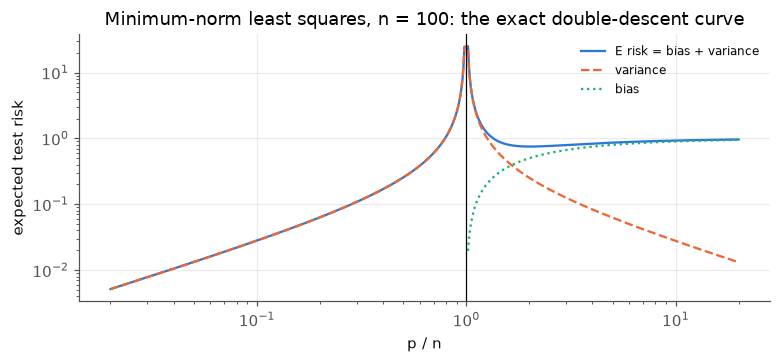

In [29]:
# Figure: the exact expected risk of the minimum-norm interpolant against p/n, split into bias and variance, with the peak at p = n
ps = np.r_[np.arange(2, n_dd - 1), np.arange(n_dd + 2, 20 * n_dd)]
eb_ = np.where(ps < n_dd, 0.0, r_dd**2 * (1 - n_dd / ps)); ev_ = np.where(ps < n_dd, sig_dd**2 * ps / (n_dd - ps - 1), sig_dd**2 * n_dd / (ps - n_dd - 1))
plt.figure(figsize=(7.2, 3.4)); plt.plot(ps / n_dd, eb_ + ev_, color=C1, label="E risk = bias + variance"); plt.plot(ps / n_dd, ev_, color=C2, ls="--", label="variance"); plt.plot(ps[ps > n_dd] / n_dd, eb_[ps > n_dd], color=C3, ls=":", label="bias")
plt.axvline(1, color="k", lw=0.8); plt.xscale("log"); plt.yscale("log"); plt.xlabel("p / n"); plt.ylabel("expected test risk"); plt.legend(fontsize=8); plt.title(f"Minimum-norm least squares, n = {n_dd}: the exact double-descent curve"); plt.show()

---
## Critic round 1 addenda (2026-10-30) — the counter-examples, computed

### §44 — Interval bound propagation with every ReLU stable is still not exact (article §8.4, exercise 17)
Two copies of $\mathrm{relu}(x+1)$ subtracted: the output is identically zero, both ReLUs are always on, and interval arithmetic returns $[-1, 1]$. A linear (symbolic) bound returns $0$.

In [30]:
sec(44, "Interval bound propagation is not exact even with every ReLU stable: two copies of one pre-activation, subtracted")
# x in [0, 1]; h1 = relu(x + 1), h2 = relu(x + 1); out = h1 - h2 = 0 for every x. Both pre-activations lie in [1, 2]: both ReLUs are stable (always on).
# Interval arithmetic carries h1 and h2 as independent intervals [1, 2] and returns out in [1 - 2, 2 - 1] = [-1, 1]: the dependency problem, not the ReLUs.
# A symbolic (linear) bound keeps out = (x + 1) - (x + 1) = 0 and is exact — which is why the verifiers of §35 propagate linear bounds (CROWN, beta-CROWN).
W1_d = np.array([[1.0], [1.0]]); b1_d = np.array([1.0, 1.0]); W2_d = np.array([1.0, -1.0]); b2_d = 0.0
lo_x, hi_x = 0.0, 1.0
lo1 = W1_d.clip(min=0) @ [lo_x] + W1_d.clip(max=0) @ [hi_x] + b1_d; hi1 = W1_d.clip(min=0) @ [hi_x] + W1_d.clip(max=0) @ [lo_x] + b1_d    # one affine layer: exact per coordinate
lo1r, hi1r = np.maximum(lo1, 0), np.maximum(hi1, 0)
lo_out = W2_d.clip(min=0) @ lo1r + W2_d.clip(max=0) @ hi1r + b2_d; hi_out = W2_d.clip(min=0) @ hi1r + W2_d.clip(max=0) @ lo1r + b2_d
xs_d = np.linspace(lo_x, hi_x, 10001); true_out = np.maximum(xs_d + 1, 0) - np.maximum(xs_d + 1, 0)
print(f"  pre-activation intervals: h1 in [{lo1[0]:.0f}, {hi1[0]:.0f}], h2 in [{lo1[1]:.0f}, {hi1[1]:.0f}]  ->  unstable ReLUs: 0/2 (both always on)")
print(f"  IBP bound on out = h1 - h2: [{lo_out:+.0f}, {hi_out:+.0f}];  true range over x in [0, 1]: [{true_out.min():+.0f}, {true_out.max():+.0f}]   (loose by 1 on each side with no unstable ReLU)")
A_sym = W2_d @ W1_d; c_sym = W2_d @ b1_d + b2_d                                            # carry each neuron as an affine function of x (exact through an always-on ReLU)
print(f"  linear (symbolic) bound: out = {A_sym[0]:+.0f} x {c_sym:+.0f}  ->  [{min(A_sym[0]*lo_x, A_sym[0]*hi_x)+c_sym:+.0f}, {max(A_sym[0]*lo_x, A_sym[0]*hi_x)+c_sym:+.0f}]: exact, because it remembers that h1 and h2 are the same function of x")
print("  (stable ReLUs remove the activation's contribution to looseness; they do not remove the dependency loss of composing affine maps through intervals — that is what linear bounds fix, and unstable ReLUs are what branching pays for)")


=== §44 Interval bound propagation is not exact even with every ReLU stable: two copies of one pre-activation, subtracted ===
  pre-activation intervals: h1 in [1, 2], h2 in [1, 2]  ->  unstable ReLUs: 0/2 (both always on)
  IBP bound on out = h1 - h2: [-1, +1];  true range over x in [0, 1]: [+0, +0]   (loose by 1 on each side with no unstable ReLU)
  linear (symbolic) bound: out = +0 x +0  ->  [+0, +0]: exact, because it remembers that h1 and h2 are the same function of x
  (stable ReLUs remove the activation's contribution to looseness; they do not remove the dependency loss of composing affine maps through intervals — that is what linear bounds fix, and unstable ReLUs are what branching pays for)


### §45 — GRPO's group-mean baseline is biased by the factor $1 - 1/G$ (article §9.2)
On a tabular softmax policy the estimator's expectation is $(1 - 1/G)\nabla J$; the leave-one-out mean is unbiased; the std-normalised advantage is not a scaled gradient and its cosine with $\nabla J$ is measured.

In [31]:
sec(45, "GRPO's group-mean baseline includes the sample's own reward: the estimator's expectation is (1 - 1/G) times the policy gradient, and leave-one-out restores it")
# Tabular softmax policy over K actions with logits theta; fixed rewards r; J(theta) = sum_a pi_a r_a; exact grad J = sum_a pi_a r_a (e_a - pi).
# Group estimator with G on-policy samples: g_hat = (1/G) sum_i (r_i - rbar) grad log pi(a_i), rbar = (1/G) sum_j r_j — which includes r_i.
# E[g_hat] = (1 - 1/G) grad J: the j = i term of the baseline is not independent of the score. Leave-one-out baseline rbar_{-i}: unbiased.
# GRPO also divides by the group's reward std: a ratio of random variables, no longer a scaled gradient in expectation; its cosine with grad J is measured.
K_g = 4; theta_g = np.array([0.5, -0.2, 0.1, -0.4]); r_g = np.array([1.0, 0.0, 0.5, 2.0])
pi_g = np.exp(theta_g) / np.exp(theta_g).sum(); grad_J = pi_g * r_g - pi_g * (pi_g @ r_g)
print(f"  pi = {pi_g}, r = {r_g}, J = {pi_g @ r_g:.4f}, ||grad J|| = {np.linalg.norm(grad_J):.4f}; 100,000 groups per G")
print("      G    <E g_hat, grad J> / ||grad J||^2:  group mean incl. self    expected 1 - 1/G    leave-one-out mean       GRPO (mean, then / std): scale and cosine with grad J")
N_g = 100000
for G_ in (2, 4, 8, 16):
    a_ = rng.choice(K_g, size=(N_g, G_), p=pi_g); r_s = r_g[a_]
    score = np.eye(K_g)[a_] - pi_g[None, None, :]                                           # grad log pi(a) = e_a - pi, shape (N_g, G, K)
    adv_mean = r_s - r_s.mean(1, keepdims=True)
    adv_loo = r_s - (r_s.sum(1, keepdims=True) - r_s) / (G_ - 1)
    sd_ = r_s.std(1, keepdims=True); adv_grpo = adv_mean / np.where(sd_ > 0, sd_, 1.0)
    g_mean = np.einsum('ng,ngk->nk', adv_mean, score) / G_; g_loo = np.einsum('ng,ngk->nk', adv_loo, score) / G_; g_grpo = np.einsum('ng,ngk->nk', adv_grpo, score) / G_
    proj = lambda g: (g.mean(0) @ grad_J) / (grad_J @ grad_J)
    proj_se = lambda g: se_mean(g @ grad_J / (grad_J @ grad_J))
    cos_ = g_grpo.mean(0) @ grad_J / (np.linalg.norm(g_grpo.mean(0)) * np.linalg.norm(grad_J))
    print(f"  {G_:5d}                                        {proj(g_mean):7.4f} ± {proj_se(g_mean):6.4f}        {1 - 1/G_:7.4f}         {proj(g_loo):7.4f} ± {proj_se(g_loo):6.4f}          scale {proj(g_grpo):7.4f}, cosine {cos_:7.4f}")
print("  (the group mean including the sample's own reward is biased by exactly the factor 1 - 1/G — a scaled gradient, so the direction survives and the learning rate absorbs the scale; the std-normalised GRPO advantage is not a scaled gradient, and the last column is how far its direction is from grad J on this problem)")


=== §45 GRPO's group-mean baseline includes the sample's own reward: the estimator's expectation is (1 - 1/G) times the policy gradient, and leave-one-out restores it ===
  pi = [0.3886 0.193  0.2605 0.158 ], r = [1.  0.  0.5 2. ], J = 0.8348, ||grad J|| = 0.2675; 100,000 groups per G
      G    <E g_hat, grad J> / ||grad J||^2:  group mean incl. self    expected 1 - 1/G    leave-one-out mean       GRPO (mean, then / std): scale and cosine with grad J
      2                                         0.4993 ± 0.0020         0.5000          0.9986 ± 0.0040          scale  0.9060, cosine  0.9640
      4                                         0.7491 ± 0.0016         0.7500          0.9989 ± 0.0021          scale  1.3283, cosine  0.9764


      8                                         0.8760 ± 0.0012         0.8750          1.0011 ± 0.0013          scale  1.4828, cosine  0.9937


     16                                         0.9385 ± 0.0008         0.9375          1.0011 ± 0.0009          scale  1.5454, cosine  0.9989
  (the group mean including the sample's own reward is biased by exactly the factor 1 - 1/G — a scaled gradient, so the direction survives and the learning rate absorbs the scale; the std-normalised GRPO advantage is not a scaled gradient, and the last column is how far its direction is from grad J on this problem)


---
## Critic round 2 addenda (2026-10-30)

### §49 — Goemans–Williamson on the triangle: the SDP relaxation is not exact (article §8.2)
Maximum cut $2$, SDP value $2.25$ (three unit vectors at $120°$), a $12.5\%$ integrality gap; hyperplane rounding recovers $2$, and the $0.878$ is a guarantee about the rounding relative to the relaxed value, not a certificate for the instance.

In [32]:
sec(49, "Goemans-Williamson on the triangle: the maximum cut is 2, the SDP relaxation's value is 2.25 (three unit vectors at 120 degrees), so the first level is NOT exact - 0.878 is an approximation ratio, not a certificate")
# max-cut on K3: maximise (1/2) sum_{edges} (1 - x_i x_j) over x in {-1, +1}^3. The SDP replaces x_i x_j by v_i . v_j with unit vectors v_i (any dimension).
# Upper bound on the SDP: ||v1 + v2 + v3||^2 >= 0 gives sum_{i<j} v_i . v_j >= -3/2, so (1/2)(3 - sum) <= (1/2)(3 + 3/2) = 2.25; three coplanar unit vectors at 120 degrees attain it.
cuts = [0.5 * sum(1 - x[i] * x[j] for i, j in ((0, 1), (1, 2), (0, 2))) for x in [(a_, b_, c_) for a_ in (-1, 1) for b_ in (-1, 1) for c_ in (-1, 1)]]
V_gw = np.array([[math.cos(2 * pi * k_ / 3), math.sin(2 * pi * k_ / 3)] for k_ in range(3)])
sdp_val = 0.5 * sum(1 - V_gw[i] @ V_gw[j] for i, j in ((0, 1), (1, 2), (0, 2)))
print(f"  integer optimum over the 8 cuts of the triangle: {max(cuts):.2f}  (any one vertex against the other two cuts 2 of the 3 edges; no cut takes all three)")
print(f"  SDP relaxation: three unit vectors at 120 degrees give (1/2) sum (1 - v_i . v_j) = (1/2) * 3 * (1 - ({V_gw[0] @ V_gw[1]:+.2f})) = {sdp_val:.2f};  Gram inequality ||v1+v2+v3||^2 >= 0 caps the relaxation at {0.5 * (3 + 1.5):.2f}: the SDP optimum is 2.25")
print(f"  integrality gap on this instance: {sdp_val / max(cuts):.4f} (the relaxation overstates the cut by {100 * (sdp_val / max(cuts) - 1):.1f}%); the SDP value is an UPPER bound on the cut, not its value")
thetas = np.linspace(1e-6, pi, 200001); gw_curve = (thetas / pi) / ((1 - np.cos(thetas)) / 2)
print(f"  hyperplane rounding on the triangle: each edge at angle 2pi/3 is cut with probability (2pi/3)/pi = {(2 * pi / 3) / pi:.4f}, expected cut = {3 * (2 * pi / 3) / pi:.4f} = the optimum, {3 * (2 * pi / 3) / pi / sdp_val:.4f} of the relaxed value")
print(f"  Goemans-Williamson's constant: min over theta of (theta/pi) / ((1 - cos theta)/2) = {gw_curve.min():.5f} at theta = {thetas[gw_curve.argmin()]:.4f} rad = {math.degrees(thetas[gw_curve.argmin()]):.1f} degrees — a guarantee about the ROUNDING, relative to the relaxed value; the instance is certified only when the rounded cut meets the SDP value")


=== §49 Goemans-Williamson on the triangle: the maximum cut is 2, the SDP relaxation's value is 2.25 (three unit vectors at 120 degrees), so the first level is NOT exact - 0.878 is an approximation ratio, not a certificate ===
  integer optimum over the 8 cuts of the triangle: 2.00  (any one vertex against the other two cuts 2 of the 3 edges; no cut takes all three)
  SDP relaxation: three unit vectors at 120 degrees give (1/2) sum (1 - v_i . v_j) = (1/2) * 3 * (1 - (-0.50)) = 2.25;  Gram inequality ||v1+v2+v3||^2 >= 0 caps the relaxation at 2.25: the SDP optimum is 2.25
  integrality gap on this instance: 1.1250 (the relaxation overstates the cut by 12.5%); the SDP value is an UPPER bound on the cut, not its value
  hyperplane rounding on the triangle: each edge at angle 2pi/3 is cut with probability (2pi/3)/pi = 0.6667, expected cut = 2.0000 = the optimum, 0.8889 of the relaxed value
  Goemans-Williamson's constant: min over theta of (theta/pi) / ((1 - cos theta)/2) = 0.87857 at the

### §51 — The Euler–Langevin chain samples a wider law than $e^{-f/T}$ (article §8.3)
On $f = x^2/2$ the discretised chain's stationary variance is $T/(1 - \eta/2)$, measured against the Gibbs target $T$: the Gibbs statement belongs to the continuous diffusion.

In [33]:
sec(51, "The Gibbs law exp(-f/T) is the stationary law of the CONTINUOUS Langevin diffusion; its Euler discretisation x <- (1 - eta) x + sqrt(2 eta T) xi on f = x^2/2 has stationary variance T / (1 - eta/2), measured")
# Continuous: dx = -x dt + sqrt(2T) dW has stationary variance T (Ornstein-Uhlenbeck). Euler at step eta: x_{t+1} = (1 - eta) x_t + sqrt(2 eta T) xi_t is an AR(1) with
# stationary variance 2 eta T / (1 - (1 - eta)^2) = T / (1 - eta/2): the discretisation samples a WIDER law than exp(-f/T), by a factor that is O(eta), and that is what a
# Metropolis correction (MALA) removes. Measured below with T = 1 on an ensemble of chains after a burn-in.
T_lan = 1.0; n_ch, n_st, burn = 2000, 4000, 1000
print("      eta     closed form T/(1 - eta/2)     measured stationary variance (2000 chains x 3000 post-burn-in steps)     Gibbs target variance T")
for eta_ in (0.5, 0.1, 0.01):
    x_ = np.zeros(n_ch); acc_ = np.zeros(n_ch); cnt_ = 0
    for t_ in range(n_st):
        x_ = (1 - eta_) * x_ + sqrt(2 * eta_ * T_lan) * rng.standard_normal(n_ch)
        if t_ >= burn: acc_ += x_ * x_; cnt_ += 1
    per_chain = acc_ / cnt_                                       # each chain's time-average of x^2; chains are independent, so the SE is over chains
    print(f"  {eta_:6.2f}          {T_lan / (1 - eta_ / 2):8.4f}                        {per_chain.mean():8.4f} ± {se_mean(per_chain):6.4f}                                         {T_lan:8.4f}")
print("  (the chain at eta = 0.5 sits a third too wide, at 0.1 five per cent, at 0.01 half a per cent: the Gibbs statement is exact for the diffusion and O(eta) wrong for the update a loop actually runs; Hajek's log-cooling theorem is about a third object again, a finite-state annealing chain)")


=== §51 The Gibbs law exp(-f/T) is the stationary law of the CONTINUOUS Langevin diffusion; its Euler discretisation x <- (1 - eta) x + sqrt(2 eta T) xi on f = x^2/2 has stationary variance T / (1 - eta/2), measured ===
      eta     closed form T/(1 - eta/2)     measured stationary variance (2000 chains x 3000 post-burn-in steps)     Gibbs target variance T
    0.50            1.3333                          1.3353 ± 0.0010                                           1.0000


    0.10            1.0526                          1.0526 ± 0.0018                                           1.0000
    0.01            1.0050                          0.9951 ± 0.0056                                           1.0000
  (the chain at eta = 0.5 sits a third too wide, at 0.1 five per cent, at 0.01 half a per cent: the Gibbs statement is exact for the diffusion and O(eta) wrong for the update a loop actually runs; Hajek's log-cooling theorem is about a third object again, a finite-state annealing chain)


### §52 — Optimistic gradient and extragradient: comparable, not identical, rates (article §9.1)
Spectral radii $0.99494$ against $0.99504$ at $\eta = 0.1$; the optimistic companion matrix is not normal, so its $200$-step norm carries a transient.

In [34]:
sec(52, "Optimistic gradient and extragradient on the bilinear saddle contract at COMPARABLE, not identical, rates: spectral radius 0.99494 vs 0.99504 at eta = 0.1")
# Extragradient on v(z) = J z: z <- (I - eta J + eta^2 J^2) z, a normal matrix, so ||z|| contracts by exactly its spectral radius sqrt(1 - eta^2 + eta^4) per step.
# Optimistic gradient (§37's update): z_{t+1} = z_t - 2 eta J z_t + eta J z_{t-1}, a two-step recursion whose 4x4 companion matrix [[I - 2 eta J, eta J], [I, 0]] is not normal:
# its spectral radius sets the asymptotic rate and its transient explains why ||z_200|| in §37 is not the 200th power of it times sqrt(2).
eta_52 = 0.1; J_52 = np.array([[0.0, 1.0], [-1.0, 0.0]]); I2 = np.eye(2)
M_eg = I2 - eta_52 * J_52 + eta_52 ** 2 * J_52 @ J_52
M_og = np.block([[I2 - 2 * eta_52 * J_52, eta_52 * J_52], [I2, np.zeros((2, 2))]])
rho_eg = np.abs(np.linalg.eigvals(M_eg)).max(); rho_og = np.abs(np.linalg.eigvals(M_og)).max()
print(f"  extragradient:  spectral radius {rho_eg:.6f} = sqrt(1 - eta^2 + eta^4) = {sqrt(1 - eta_52 ** 2 + eta_52 ** 4):.6f};  rho^200 * sqrt(2) = {rho_eg ** 200 * sqrt(2):.4f}  (§37 printed 5.2290e-01: exact, the matrix is normal)")
print(f"  optimistic:     spectral radius {rho_og:.6f};                                      rho^200 * sqrt(2) = {rho_og ** 200 * sqrt(2):.4f}  (§37 printed 5.1762e-01: the companion matrix is not normal, so the 200-step norm carries a transient)")
print(f"  ratio of the two per-step factors: {rho_og / rho_eg:.6f}; over 200 steps the optimistic method is ahead by a factor {(rho_eg / rho_og) ** 200:.4f} — comparable geometric rates, the same O(1/T) duality-gap theorem (Nemirovski 2004; Mokhtari, Ozdaglar & Pattathil 2020 for the optimistic method), not the same number")


=== §52 Optimistic gradient and extragradient on the bilinear saddle contract at COMPARABLE, not identical, rates: spectral radius 0.99494 vs 0.99504 at eta = 0.1 ===
  extragradient:  spectral radius 0.995038 = sqrt(1 - eta^2 + eta^4) = 0.995038;  rho^200 * sqrt(2) = 0.5229  (§37 printed 5.2290e-01: exact, the matrix is normal)
  optimistic:     spectral radius 0.994936;                                      rho^200 * sqrt(2) = 0.5123  (§37 printed 5.1762e-01: the companion matrix is not normal, so the 200-step norm carries a transient)
  ratio of the two per-step factors: 0.999898; over 200 steps the optimistic method is ahead by a factor 1.0206 — comparable geometric rates, the same O(1/T) duality-gap theorem (Nemirovski 2004; Mokhtari, Ozdaglar & Pattathil 2020 for the optimistic method), not the same number


---
## Critic round 3 addendum (2026-10-30)

### §53 — The §22 table read correctly: $T^{-3/2}$, not $T^{-2}$ (article §6.2)
The printed column is the *squared* gradient norm; a log–log fit over the four rows gives slope $\approx -1.50$, so the ratio to the $O(1/T)$ bound falls like $T^{-1/2}$ and the unsquared norm like $T^{-3/4}$.

In [35]:
sec(53, "The §22 table read correctly: on the convex chain min_t ||grad||^2 falls like T^-3/2, so the ratio to the O(1/T) bound falls like T^-1/2 (not T^-2 and T^-1)")
# round-3 addendum (no draws): recompute §22's deterministic GD run on Nesterov's chain and fit log-log slopes to the four printed rows.
d53 = 2001; L53 = 1.0
def f_53(x): return L53 / 4 * (0.5 * (x[0] ** 2 + np.sum((x[:-1] - x[1:]) ** 2) + x[-1] ** 2) - x[0])
def g_53(x):
    g = np.zeros_like(x); dif = x[:-1] - x[1:]
    g[0] += x[0]; g[:-1] += dif; g[1:] -= dif; g[-1] += x[-1]; g[0] -= 1
    return L53 / 4 * g
xs53 = 1 - np.arange(1, d53 + 1) / (d53 + 1); fs53 = f_53(xs53)
x53 = np.zeros(d53); f053 = f_53(x53); gm53 = np.inf; rows53 = []
for t in range(1, 10001):
    g = g_53(x53); gm53 = min(gm53, g @ g); x53 = x53 - g / L53
    if t in (10, 100, 1000, 10000): rows53.append((t, gm53, 2 * L53 * (f053 - fs53) / t))
Ts = np.array([r[0] for r in rows53], float); G2 = np.array([r[1] for r in rows53]); Bd = np.array([r[2] for r in rows53])
slope_g2 = np.polyfit(np.log(Ts), np.log(G2), 1)[0]; slope_ratio = np.polyfit(np.log(Ts), np.log(G2 / Bd), 1)[0]
print("      T    min_t ||grad||^2   per-decade factor   (same run as §22; the printed column is the SQUARED norm)")
for i, (t, g2, b) in enumerate(rows53):
    print(f"  {t:6d}    {g2:14.3e}   {'' if i == 0 else f'{rows53[i-1][1] / g2:8.2f}':>8s}")
print(f"  log-log slope of min_t ||grad||^2 against T: {slope_g2:.3f}  (T^-3/2 would be -1.500; a factor {10 ** 1.5:.1f} per decade, not 100)")
print(f"  log-log slope of the ratio to the bound 2L(f0 - f*)/T: {slope_ratio:.3f}  (the bound is exactly T^-1, so ratio ~ T^{slope_g2 + 1:+.3f})")
print(f"  unsquared ||grad|| therefore falls like T^{slope_g2 / 2:.3f}; the earlier prose's 'gradient norm decays like 1/T^2' and 'ratio falls like 1/T' were misreadings of this table, corrected in round 3")


=== §53 The §22 table read correctly: on the convex chain min_t ||grad||^2 falls like T^-3/2, so the ratio to the O(1/T) bound falls like T^-1/2 (not T^-2 and T^-1) ===


      T    min_t ||grad||^2   per-decade factor   (same run as §22; the printed column is the SQUARED norm)
      10         1.607e-03           
     100         4.996e-05      32.17
    1000         1.577e-06      31.68
   10000         4.987e-08      31.63
  log-log slope of min_t ||grad||^2 against T: -1.503  (T^-3/2 would be -1.500; a factor 31.6 per decade, not 100)
  log-log slope of the ratio to the bound 2L(f0 - f*)/T: -0.503  (the bound is exactly T^-1, so ratio ~ T^-0.503)
  unsquared ||grad|| therefore falls like T^-0.751; the earlier prose's 'gradient norm decays like 1/T^2' and 'ratio falls like 1/T' were misreadings of this table, corrected in round 3
